# TRIAD Detox: Config F (R_cov) 3-Seed Benchmark Pipeline
Preserve R_cov reward and weights of original Config F.

## Stage 1: Setup & Dependencies

In [3]:
!pip install -q "trl==0.11.4" transformers sentence-transformers accelerate pandas scipy matplotlib

from google.colab import drive
drive.mount('/content/drive')

import os, time, math, random, logging, json as pyjson, re, glob
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.INFO, format='%(asctime)s [%(levelname)s] %(message)s')
logger = logging.getLogger('RL-Pipeline')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
logger.info(f'Device: {DEVICE}')
assert os.path.exists('/content/drive/MyDrive'), 'Google Drive is not mounted! Please run drive.mount() or set local paths.'

import trl
logger.info(f'trl version: {trl.__version__} (expected 0.11.4)')

DATA_DIR = '/content/drive/MyDrive/Data_Khoaluan/03_stratified_benchmark'
T5_SFT_DIR = '/content/drive/MyDrive/Data_Khoaluan/T5_base'
RL_OUTPUT_DIR = '/content/drive/MyDrive/Data_Khoaluan/ppo_config_f_v1'
RESULTS_DIR = os.path.join(RL_OUTPUT_DIR, 'final_results')
os.makedirs(RL_OUTPUT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

SEED_LIST = [42, 123, 777]
logger.info(f'DATA_DIR={DATA_DIR} | T5_SFT_DIR={T5_SFT_DIR} | RL_OUTPUT_DIR={RL_OUTPUT_DIR}')
logger.info(f'SEED_LIST: {SEED_LIST}')

# === Config F: only save new Post-Val results to dedicated folder ===
CONFIG_NAME = 'F'
CKPT_ROOT = RL_OUTPUT_DIR
NEW_RESULTS_DIR = os.path.join(RL_OUTPUT_DIR, 'final_results_postval_fixed')
for _sub in ['attempts','master_tables','original_fallback_A','original_fallback_B',
             'converted_fallback_A','converted_fallback_B','diagnostics','ppl','summary']:
    os.makedirs(os.path.join(NEW_RESULTS_DIR, _sub), exist_ok=True)


Mounted at /content/drive


## Stage 1b: Optional Checkpoint & Output Reset

**Run this cell only once if you wish to reset checkpoints and outputs** — if resuming mid-run, DO NOT run this cell as it will delete all progress.

In [4]:
import shutil

CONFIRM_DELETE = False  # Set to True and re-run this cell only if you REALLY want to delete everything

if CONFIRM_DELETE:
    for SEED in SEED_LIST:
        seed_dir = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
        if os.path.exists(seed_dir):
            shutil.rmtree(seed_dir)
            print(f'Deleted checkpoint for Seed {SEED}.')
    old_files = glob.glob(os.path.join(RESULTS_DIR, '*_seed*.csv'))
    old_files += glob.glob(os.path.join(RESULTS_DIR, 'baseline_per_sample.csv'))
    for f in old_files:
        os.remove(f)
    print(f'Deleted {len(old_files)} legacy CSV files.')
else:
    print('CONFIRM_DELETE=False — Skipping deletion. Set CONFIRM_DELETE = True to reset outputs.')

CONFIRM_DELETE=False — nothing is deleted. Set to True if you want to wipe everything and restart from scratch.


## Stage 2: Load Stratified Benchmark Dataset

In [5]:
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
val_df   = pd.read_csv(os.path.join(DATA_DIR, 'val.csv'))
test_df  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))

train_toxic = train_df.reset_index(drop=True)
val_toxic   = val_df.reset_index(drop=True)
test_toxic  = test_df.reset_index(drop=True)
val_texts_all = val_toxic['text'].tolist()   # FULL Val — NO subsampling

logger.info(f'Loaded dataset: train={len(train_toxic)}, val={len(val_toxic)}, test={len(test_toxic)}.')
print(train_toxic['band'].value_counts())

band
easy      1149
medium     754
hard       521
Name: count, dtype: int64


## Stage 3-9: Reward Functions (Standard Per-Sample Formulation)

In [6]:
from transformers import T5TokenizerFast, AutoTokenizer, AutoModelForSequenceClassification
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
from sentence_transformers import SentenceTransformer
import torch.nn.functional as F

tokenizer = T5TokenizerFast.from_pretrained(T5_SFT_DIR)
TASK_PREFIX = 'detoxify: '
MAX_SOURCE_LEN = 256
MAX_NEW_TOKENS = 128

def to_list(x):
    if torch.is_tensor(x): return x.detach().cpu().tolist()
    if isinstance(x, np.ndarray): return x.tolist()
    return list(x)

tox_tokenizer = AutoTokenizer.from_pretrained('unitary/unbiased-toxic-roberta')
tox_model = AutoModelForSequenceClassification.from_pretrained('unitary/unbiased-toxic-roberta').to(DEVICE)
tox_model.eval()
id2label = tox_model.config.id2label
TOX_IDX = next((int(i) for i, l in id2label.items() if str(l).lower() in {'toxic','toxicity'}), 0)

@torch.no_grad()
def compute_r_tox(texts):
    enc = tox_tokenizer(texts, return_tensors='pt', padding=True, truncation=True, max_length=256).to(DEVICE)
    probs = torch.sigmoid(tox_model(**enc).logits.float())[:, TOX_IDX]
    return to_list(1.0 - probs)

sbert_model = SentenceTransformer('sentence-transformers/all-mpnet-base-v2', device=DEVICE)

def compute_r_sem(X_texts, Y_texts):
    eX = sbert_model.encode(X_texts, convert_to_tensor=True, device=DEVICE)
    eY = sbert_model.encode(Y_texts, convert_to_tensor=True, device=DEVICE)
    return to_list((F.cosine_similarity(eX, eY, dim=1) + 1.0) / 2.0)

gpt2_tokenizer = GPT2TokenizerFast.from_pretrained('gpt2')
gpt2_model = GPT2LMHeadModel.from_pretrained('gpt2').to(DEVICE)
gpt2_model.eval()
MAX_LOSS_CLAMP = 20.0

@torch.no_grad()
def compute_perplexity(text):
    enc = gpt2_tokenizer(text, return_tensors='pt', truncation=True, max_length=256).to(DEVICE)
    if enc.input_ids.size(1) < 2:
        return 1.0
    loss = torch.clamp(gpt2_model(enc.input_ids, labels=enc.input_ids).loss, max=MAX_LOSS_CLAMP)
    return torch.exp(loss).item()

def compute_r_flu(texts):
    """Standard per-sample evaluation (unbatched)."""
    return [1.0 / (1.0 + math.log(max(compute_perplexity(t), 1.0 + 1e-6)) / 5.0) for t in texts]

def compute_r_len(X_texts, Y_texts):
    rewards = []
    for x, y in zip(X_texts, Y_texts):
        x_len, y_len = max(len(x.split()), 1), len(y.split())
        ratio = y_len / x_len
        if 0.7 <= ratio <= 1.3: r = 1.0
        elif ratio < 0.7: r = y_len / (0.7 * x_len)
        else: r = (1.3 * x_len) / max(y_len, 1)
        rewards.append(r)
    return rewards

POLITENESS_LEXICON = [
    'please', 'could you', 'would you', 'might you', 'can you', 'will you',
    'hi', 'hello', 'hey', 'greetings', 'howdy', 'good morning', 'good evening', 'good afternoon',
    'goodbye', 'bye', 'see you later', 'thank', 'grateful', 'gratitude',
    'sorry', 'woops', 'oops', 'whoops', 'apologize',
    'is okay', 'not worry', 'no big deal', 'not a big deal', 'no problem', 'no worries',
    'is fine', 'you are good', "it's fine", "it's okay", 'let me know', 'for you',
]
P_SIZE = len(POLITENESS_LEXICON)

def compute_r_pol(Y_texts):
    return [min(sum(1 for w in POLITENESS_LEXICON if w in y.lower()) / P_SIZE, 1.0) for y in Y_texts]

# --- R_cov: content-word coverage (recall), mask toxic tokens before comparison — directly integrated into reward ---
!pip install -q spacy transformers-interpret
import spacy
import pickle
try:
    nlp_cov = spacy.load('en_core_web_sm')
except OSError:
    !python -m spacy download en_core_web_sm
    nlp_cov = spacy.load('en_core_web_sm')

from transformers_interpret import SequenceClassificationExplainer
cov_explainer = SequenceClassificationExplainer(tox_model, tox_tokenizer)  # reuse existing tox_model above

CONTENT_POS = {'NOUN', 'PROPN', 'VERB', 'ADJ', 'ADV'}  # Jurafsky & Martin — open class (content words), NO lemmatization
CW_MASKED_CACHE = {}  # content_words(X) with toxic words masked — computed once per input X, reused thereafter

def content_words(text):
    return {tok.text.lower() for tok in nlp_cov(text) if tok.pos_ in CONTENT_POS}

def toxic_words(text, threshold=0.3):
    attrs = cov_explainer(text, class_name=id2label[TOX_IDX])
    return {w.lower() for w, score in attrs if score > threshold}

def compute_r_cov(X_texts, Y_texts):
    rewards = []
    for x, y in zip(X_texts, Y_texts):
        if x not in CW_MASKED_CACHE:
            CW_MASKED_CACHE[x] = content_words(x) - toxic_words(x)
        cwx = CW_MASKED_CACHE[x]
        cwy = content_words(y)
        inter = len(cwx & cwy)
        rewards.append(inter / max(len(cwx), 1))   # recall
    return rewards

# Precompute cache for all train_toxic (X fixed, reused across steps) — run once, save pickle
CW_CACHE_PATH = os.path.join(RESULTS_DIR, 'cw_masked_cache.pkl')
if os.path.exists(CW_CACHE_PATH):
    with open(CW_CACHE_PATH, 'rb') as f:
        CW_MASKED_CACHE.update(pickle.load(f))
    logger.info(f'[R_cov cache] Already cached — {len(CW_MASKED_CACHE)} inputs X.')
else:
    for i, x in enumerate(train_toxic['text'].unique()):
        if x not in CW_MASKED_CACHE:
            CW_MASKED_CACHE[x] = content_words(x) - toxic_words(x)
        if (i + 1) % 200 == 0:
            logger.info(f'[R_cov cache] {i+1} inputs X processed.')
    with open(CW_CACHE_PATH, 'wb') as f:
        pickle.dump(CW_MASKED_CACHE, f)
    logger.info(f'[R_cov cache] Calculation complete, cached {len(CW_MASKED_CACHE)} inputs X.')

def compute_r_total(X_texts, Y_texts, weights):
    r_tox, r_sem, r_flu = compute_r_tox(Y_texts), compute_r_sem(X_texts, Y_texts), compute_r_flu(Y_texts)
    r_len, r_pol = compute_r_len(X_texts, Y_texts), compute_r_pol(Y_texts)
    w_cov = weights.get('cov', 0.0)                                    # default 0 -> identical to LEGACY behavior
    r_cov = compute_r_cov(X_texts, Y_texts) if w_cov > 0 else [0.0] * len(Y_texts)
    total = [weights['tox']*r_tox[i] + weights['sem']*r_sem[i] + weights['flu']*r_flu[i]
             + weights['len']*r_len[i] + weights['pol']*r_pol[i] + w_cov*r_cov[i] for i in range(len(Y_texts))]
    return total, {'r_tox':r_tox,'r_sem':r_sem,'r_flu':r_flu,'r_len':r_len,'r_pol':r_pol,'r_cov':r_cov}

logger.info('Reward functions (standard, non-batched), including R_cov, ready.')

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/997 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.9/45.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 43.0 MB/s eta 0:00:00


## Stage 10: PPO Configuration

In [7]:
from trl import PPOTrainer, PPOConfig, AutoModelForSeq2SeqLMWithValueHead, create_reference_model

BETA_KL, CLIP_EPS, GAE_GAMMA, GAE_LAMBDA = 0.05, 0.2, 0.99, 0.95
LEARNING_RATE, PPO_BATCH_SIZE, PPO_MINI_BATCH_SIZE = 1.4e-5, 8, 4

ppo_config = PPOConfig(
    learning_rate=LEARNING_RATE, batch_size=PPO_BATCH_SIZE, mini_batch_size=PPO_MINI_BATCH_SIZE,
    ppo_epochs=4, init_kl_coef=BETA_KL, cliprange=CLIP_EPS, cliprange_value=CLIP_EPS,
    gamma=GAE_GAMMA, lam=GAE_LAMBDA,
)
logger.info('PPOConfig ready.')

/usr/local/lib/python3.13/dist-packages/trl/trainer/ppo_config.py:207: FutureWarning: `PPOConfig` is deprecated and will be removed in the future. Please use `PPOv2Config` with `PPOv2Trainer` instead.
  warnings.warn(


## Stage 11: Generation, EarlyStopper & Phase Runner with Diagnostics

`CHECK_EVERY_STEPS=10` + FULL Val (standard evaluation, no subsampling). `run_phase_with_diagnostics` logs `stats` (reward/KL/policy_loss) at each step to CSV.

In [8]:
EVAL_BATCH_SIZE = 16
CHECK_EVERY_STEPS = 10   # Evaluates every 10 steps
MAX_STEPS_PER_PHASE = 200
# No VAL_SUBSAMPLE_SIZE — evaluate_on_val uses FULL val_texts

def generate_batch_deterministic(model, texts, batch_size=EVAL_BATCH_SIZE, max_new_tokens=MAX_NEW_TOKENS):
    results = []
    n_batches = math.ceil(len(texts) / batch_size)
    for bi in range(n_batches):
        batch_texts = texts[bi*batch_size:(bi+1)*batch_size]
        inputs = [TASK_PREFIX + t for t in batch_texts]
        try:
            enc = tokenizer(inputs, return_tensors='pt', padding=True, truncation=True, max_length=MAX_SOURCE_LEN).to(DEVICE)
            with torch.no_grad():
                out_ids = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, num_beams=4)
            results.extend([tokenizer.decode(o, skip_special_tokens=True) for o in out_ids])
        except RuntimeError as e:
            logger.error(f'Batch {bi} error: {e}. Falling back to sentence-by-sentence evaluation.')
            for t in batch_texts:
                try:
                    enc1 = tokenizer(TASK_PREFIX+t, return_tensors='pt', truncation=True, max_length=MAX_SOURCE_LEN).to(DEVICE)
                    with torch.no_grad():
                        o = model.generate(**enc1, max_new_tokens=max_new_tokens, do_sample=False, num_beams=4)
                    results.append(tokenizer.decode(o[0], skip_special_tokens=True))
                except Exception as e2:
                    logger.error(f'Failed single sentence: {e2}')
                    results.append(t)
    return results

def evaluate_on_val(model, val_texts, weights):
    """Use FULL val_texts (standard evaluation, no subsampling)."""
    Y_val = generate_batch_deterministic(model, val_texts)
    rewards, _ = compute_r_total(val_texts, Y_val, weights)
    return float(np.mean(rewards))

class EarlyStopper:
    def __init__(self, patience=3):
        self.patience, self.best_score, self.num_bad_checks, self.should_stop = patience, -float('inf'), 0, False
    def check(self, score, step):
        if score > self.best_score:
            self.best_score, self.num_bad_checks = score, 0
            logger.info(f'[EarlyStop] step={step} J_val={score:.4f} -> IMPROVEMENT.')
            return True
        self.num_bad_checks += 1
        if self.num_bad_checks >= self.patience:
            self.should_stop = True
            logger.warning('[EarlyStop] Early stopping: patience exhausted — STOP.')
        return False

def run_phase_with_diagnostics(phase_name, phase_train_df, weights, val_texts,
                                  policy_model, ppo_trainer, save_dir_base, patience=3):
    """Log stats (reward/KL/policy_loss) at each step to CSV for diagnostics."""
    logger.info(f'STARTING {phase_name} — {len(phase_train_df)} rows, weights={weights}')
    stopper = EarlyStopper(patience=patience)
    texts_all = phase_train_df['text'].tolist()
    step = 0
    t_start = time.time()
    diagnostics = []

    while step < MAX_STEPS_PER_PHASE and not stopper.should_stop:
        idx = random.sample(range(len(texts_all)), min(PPO_BATCH_SIZE, len(texts_all)))
        X_batch = [texts_all[i] for i in idx]
        query_tensors = [tokenizer(TASK_PREFIX+x, return_tensors='pt', truncation=True,
                                     max_length=MAX_SOURCE_LEN).input_ids[0].to(DEVICE) for x in X_batch]
        response_tensors = ppo_trainer.generate(query_tensors, max_new_tokens=MAX_NEW_TOKENS,
                                                   do_sample=True, top_k=0, top_p=1.0, pad_token_id=tokenizer.pad_token_id)
        Y_batch = [tokenizer.decode(r, skip_special_tokens=True) for r in response_tensors]
        rewards_list, _ = compute_r_total(X_batch, Y_batch, weights)
        reward_tensors = [torch.tensor(r, dtype=torch.float32) for r in rewards_list]

        stats = ppo_trainer.step(query_tensors, response_tensors, reward_tensors)
        step += 1

        diagnostics.append({
            'step': step,
            'mean_reward': float(np.mean(rewards_list)),
            'kl': stats.get('objective/kl'),
            'policy_loss': stats.get('ppo/loss/policy'),
        })

        if step % 5 == 0:
            logger.info(f'[{phase_name}] step={step} R={np.mean(rewards_list):.4f} '
                        f'KL={diagnostics[-1]["kl"]} policy_loss={diagnostics[-1]["policy_loss"]}')

        if step % CHECK_EVERY_STEPS == 0:
            j_val = evaluate_on_val(policy_model, val_texts, weights)
            if stopper.check(j_val, step):
                save_dir = os.path.join(save_dir_base, phase_name.lower().replace(' ', '_'))
                policy_model.save_pretrained(save_dir)
                tokenizer.save_pretrained(save_dir)

    elapsed = time.time() - t_start
    logger.info(f'{phase_name} COMPLETED after {step} steps, {elapsed/60:.1f} mins. Best={stopper.best_score:.4f}')

    diag_df = pd.DataFrame(diagnostics)
    diag_path = os.path.join(save_dir_base, f'diagnostics_{phase_name.lower()}.csv')
    diag_df.to_csv(diag_path, index=False)
    logger.info(f'Saved training curves: {diag_path}')
    return stopper.best_score

logger.info('generate/EarlyStopper/run_phase_with_diagnostics ready.')

## Stage 17-18: Post-Validation & Checkpoint Evaluation

In [9]:
# Cell 15A — Fluency threshold conversion using standard log-scale calibration.
FLU_THRESHOLD_ORIG = 0.70
FLU_SCALE = 5.0
TARGET_PPL = 10 ** (FLU_SCALE * (1 / FLU_THRESHOLD_ORIG - 1))
FLU_THRESHOLD_CONVERTED = 1 / (1 + math.log(TARGET_PPL) / FLU_SCALE)
assert abs(FLU_THRESHOLD_CONVERTED - 0.5033) < 1e-3
FLU_THRESHOLDS = {'original': FLU_THRESHOLD_ORIG, 'converted': FLU_THRESHOLD_CONVERTED}
pd.DataFrame([{'original_threshold':FLU_THRESHOLD_ORIG,
               'target_ppl_log10_assumption':TARGET_PPL,
               'converted_threshold_ln':FLU_THRESHOLD_CONVERTED,
               'assumption':'original 0.70 interpreted on log10(PPL) scale'}]).to_csv(
    os.path.join(NEW_RESULTS_DIR,'threshold_conversion.csv'),index=False)
print('FLU_THRESHOLDS:', FLU_THRESHOLDS, 'PPL target:', TARGET_PPL)

FLU_THRESHOLDS: {'original': 0.7, 'converted': 0.5033163051537607} PPL target: 138.9495494373139


In [10]:
# Original Cell 15 — ONLY criteria and decision functions; does not call model.generate.
TAU_REDETECT, SEM_THRESHOLD, MAX_REGEN_ATTEMPTS = 0.30, 0.70, 3
TEMPERATURES = {1: None, 2: 0.9, 3: 1.1}

def annotate_attempts(log_df, threshold):
    d = log_df.copy()
    d['fail_toxicity'] = d['tox'] >= TAU_REDETECT
    d['fail_semantic'] = d['sem'] <= SEM_THRESHOLD
    d['fail_fluency'] = d['flu'] <= threshold     # strict PASS >
    d['fail_short'] = d['ratio'] < 0.7
    d['fail_long'] = d['ratio'] > 1.3
    d['fail_length'] = d['fail_short'] | d['fail_long']
    d['fail_any'] = d[['fail_toxicity','fail_semantic','fail_fluency','fail_length']].any(axis=1)
    d['pass'] = ~d['fail_any']
    return d

def select_postval(log_df, threshold, fallback):
    # log_df contains 1–3 rows per sample; stops at first passing attempt.
    d = annotate_attempts(log_df.sort_values('attempt'),threshold)
    assert int(d.iloc[0]['attempt']) == 1
    passed = d[~d['fail_any']]
    if len(passed):
        selected = passed.iloc[0]
        attempted = int(selected['attempt'])
        failed_all = False
    else:
        assert int(d.iloc[-1]['attempt']) == 3, 'Missing attempt 3 for fail-all sample'
        selected = d.iloc[-1] if fallback == 'A' else d.iloc[0]
        attempted = 3
        failed_all = True
    return {'Y':str(selected['Y']), 'accepted_attempt':int(selected['attempt']),
            'n_attempts':attempted, 'regenerated':attempted>1,
            'failed_all':failed_all, 'accepted':not failed_all,
            'manual_review':bool(failed_all and fallback=='B'),
            'fallback_rule':fallback if failed_all else 'first_pass'}

def summarize(df):
    cols = ['STA','STA (indep.)','Sim','Flu','Joint']
    return {m:float(df[m].mean()) for m in cols if m in df.columns and len(df)}

# evaluate_checkpoint now only retains the deterministic path used for baseline / phase.
def evaluate_checkpoint(model, eval_df):
    X = eval_df['text'].astype(str).tolist()
    Y = generate_batch_deterministic(model, X)
    # Do not use N4 scoring in legacy baseline to preserve baseline code integrity.
    sta = compute_r_tox(Y)
    sim = compute_r_sem(X,Y)
    flu = compute_r_flu(Y)
    joint = [(max(s,0)*max(si,0)*max(f,0))**(1/3) for s,si,f in zip(sta,sim,flu)]
    df = pd.DataFrame({'X':X,'Y':Y,'label':eval_df['label'].tolist(),
                       'band':eval_df['band'].tolist(),'STA':sta,'Sim':sim,'Flu':flu,'Joint':joint})
    return df, None

In [11]:
# Cell 15B — candidate generation, common scoring, single source of truth.
import hashlib, platform, datetime, gc
from transformers import AutoTokenizer, AutoModelForSequenceClassification

_INDEP_MODEL = None
_INDEP_TOKENIZER = None
_INDEP_TOX_INDEX = None

def get_independent_evaluator():
    global _INDEP_MODEL, _INDEP_TOKENIZER, _INDEP_TOX_INDEX
    if _INDEP_MODEL is None:
        _INDEP_TOKENIZER = AutoTokenizer.from_pretrained('s-nlp/roberta_toxicity_classifier')
        _INDEP_MODEL = AutoModelForSequenceClassification.from_pretrained(
            's-nlp/roberta_toxicity_classifier').to(DEVICE).eval()
        _INDEP_TOX_INDEX = next((int(i) for i,l in _INDEP_MODEL.config.id2label.items()
                                 if str(l).lower() in {'toxic','toxicity'}), 1)
    return _INDEP_MODEL

@torch.no_grad()
def compute_sta_indep(texts, batch_size=16):
    model = get_independent_evaluator()
    vals = []
    for k in range(0,len(texts),batch_size):
        bt = [str(t) for t in texts[k:k+batch_size]]
        enc = _INDEP_TOKENIZER(bt,return_tensors='pt',padding=True,
                                truncation=True,max_length=256).to(DEVICE)
        probs = torch.softmax(model(**enc).logits.float(),dim=-1)[:,_INDEP_TOX_INDEX]
        vals.extend((1-probs).cpu().tolist())
    return vals

def score_outputs(X, Y, labels=None, bands=None):
    # Score all outputs with a single function, compute per-sample Joint before mean.
    X, Y = list(map(str,X)), list(map(str,Y))
    assert len(X) == len(Y)
    if not X:
        return pd.DataFrame(columns=['X','Y','STA','STA (indep.)','Sim','Flu','PPL','Joint','ratio','tox'])
    sta, indep, sim = [], [], []
    for j in range(0,len(Y),16):
        sta.extend(compute_r_tox(Y[j:j+16]))
        indep.extend(compute_sta_indep(Y[j:j+16]))
        sim.extend(compute_r_sem(X[j:j+16],Y[j:j+16]))
    ppl = [compute_perplexity(y) for y in Y]
    flu = [1/(1+math.log(max(v,1+1e-6))/FLU_SCALE) for v in ppl]
    ratio = [len(y.split())/max(len(x.split()),1) for x,y in zip(X,Y)]
    joint = [(max(a,0)*max(b,0)*max(c,0))**(1/3) for a,b,c in zip(sta,sim,flu)]
    res = pd.DataFrame({'X':X,'Y':Y,'STA':sta,'STA (indep.)':indep,
                        'Sim':sim,'Flu':flu,'PPL':ppl,'Joint':joint,
                        'ratio':ratio,'tox':[1-s for s in sta]})
    if labels is not None: res['label'] = list(labels)
    if bands is not None: res['band'] = list(bands)
    return res

def candidate_seed(seed, idx, attempt):
    return (int(seed)*1_000_003+int(idx))*10+int(attempt)

def generate_candidate(model, x, seed, idx, attempt):
    assert attempt in (2,3)
    rng_seed = candidate_seed(seed,idx,attempt)
    random.seed(rng_seed)
    np.random.seed(rng_seed%(2**32))
    torch.manual_seed(rng_seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(rng_seed)
    enc = tokenizer(TASK_PREFIX+str(x),return_tensors='pt',truncation=True,
                    max_length=MAX_SOURCE_LEN).to(DEVICE)
    with torch.no_grad():
        ids=model.generate(**enc,max_new_tokens=MAX_NEW_TOKENS,do_sample=True,
                           temperature=TEMPERATURES[attempt],top_k=0,top_p=1.0)
    return tokenizer.decode(ids[0],skip_special_tokens=True)

def sample_hash(y):
    return hashlib.sha256(str(y).encode('utf-8')).hexdigest()

def load_phase3_reference(seed):
    path=os.path.join(RESULTS_DIR,f'per_sample_seed{seed}_phase3_refinement.csv')
    assert os.path.isfile(path), f'Missing ORIGINAL Phase 3 output: {path}'
    df=pd.read_csv(path,keep_default_na=False)
    assert len(df)==len(test_toxic),(seed,len(df),len(test_toxic))
    assert df['X'].astype(str).tolist()==test_toxic['text'].astype(str).tolist(), \
           f'Phase 3 input mismatch with test_toxic by idx (seed {seed})'
    return df,path

def _checkpoint_path(seed):
    return os.path.join(CKPT_ROOT,f'seed_{seed}','phase3_refinement')

def generate_seed_log(seed, rerun=False):
    p3,src = load_phase3_reference(seed)
    out=os.path.join(NEW_RESULTS_DIR,'attempts',f'attempts_seed{seed}.csv')
    saved=pd.read_csv(out,keep_default_na=False) if os.path.exists(out) and not rerun else pd.DataFrame()
    n=len(p3)
    if len(saved):
        assert {'seed','idx','attempt','X','Y','tox','sem','flu','ppl','ratio','Y_sha256'}.issubset(saved.columns)
        assert not saved.duplicated(['idx','attempt']).any()
        assert set(saved['seed'].astype(int))=={seed}
        for _,r in saved.iterrows():
            i=int(r['idx']);a=int(r['attempt'])
            assert 0<=i<n and 1<=a<=3 and r['X']==str(p3.iloc[i]['X'])
            assert r['Y_sha256']==sample_hash(r['Y'])
            if a==1: assert r['Y']==str(p3.iloc[i]['Y'])
    records = saved.to_dict('records') if len(saved) else []
    known={(int(r['idx']),int(r['attempt'])):r for r in records}
    model=None
    try:
        for idx in range(n):
            x=str(p3.iloc[idx]['X'])
            for attempt in (1,2,3):
                if (idx,attempt) in known:
                    row=known[(idx,attempt)]
                else:
                    # Only generate if at least one of the two thresholds still fails.
                    if attempt==1:
                        y=str(p3.iloc[idx]['Y'])
                    else:
                        if model is None:
                            checkpoint=_checkpoint_path(seed)
                            assert os.path.isdir(checkpoint), f'Missing checkpoint: {checkpoint}'
                            model=AutoModelForSeq2SeqLMWithValueHead.from_pretrained(checkpoint).to(DEVICE).eval()
                        y=generate_candidate(model,x,seed,idx,attempt)
                    scored=score_outputs([x],[y]).iloc[0]
                    row={'seed':seed,'idx':idx,'attempt':attempt,
                         'temp':'beam4' if attempt==1 else str(TEMPERATURES[attempt]),
                         'X':x,'Y':y,'Y_sha256':sample_hash(y),
                         'tox':float(scored['tox']),'sem':float(scored['Sim']),
                         'flu':float(scored['Flu']),'ppl':float(scored['PPL']),
                         'ratio':float(scored['ratio']),
                         'generation_seed':None if attempt==1 else candidate_seed(seed,idx,attempt)}
                    records.append(row)
                    known[(idx,attempt)]=row
                    # Checkpoint-safe cache: saves each output immediately, does not overwrite source.
                    pd.DataFrame(records).sort_values(['idx','attempt']).to_csv(out,index=False)
                # When passing BOTH thresholds, both branches terminate without further generation.
                if all(not bool(annotate_attempts(pd.DataFrame([row]),th).iloc[0]['fail_any'])
                       for th in FLU_THRESHOLDS.values()):
                    break
                # When one threshold passed in a previous attempt, does the other branch remain?
                seq=pd.DataFrame([known[(idx,a)] for a in range(1,attempt+1)])
                if all((~annotate_attempts(seq,th)['fail_any']).any()
                       for th in FLU_THRESHOLDS.values()):
                    break
        log=pd.DataFrame(records).sort_values(['idx','attempt']).reset_index(drop=True)
        # Log fail flags of both thresholds to long log, do not generate further candidates.
        for rule,threshold in FLU_THRESHOLDS.items():
            rated=annotate_attempts(log,threshold)
            for col in ['fail_toxicity','fail_semantic','fail_fluency',
                        'fail_length','fail_short','fail_long','fail_any','pass']:
                log[f'{rule}_{col}']=rated[col].astype(bool).to_numpy()
        log.to_csv(out,index=False)
        return log
    finally:
        if model is not None:
            del model
            gc.collect()
            if torch.cuda.is_available():torch.cuda.empty_cache()

def evaluate_seed(seed):
    log=generate_seed_log(seed)
    p3,_=load_phase3_reference(seed)
    for name,threshold in FLU_THRESHOLDS.items():
        for fallback in ('A','B'):
            subfolder=os.path.join(NEW_RESULTS_DIR,f'{name}_fallback_{fallback}')
            rows=[]
            for idx,g in log.groupby('idx',sort=True):
                dec=select_postval(g,threshold,fallback)
                rows.append({'idx':int(idx),**dec})
            decisions=pd.DataFrame(rows).sort_values('idx').reset_index(drop=True)
            assert len(decisions)==len(p3)
            scored=score_outputs(p3['X'].tolist(),decisions['Y'].tolist(),
                                p3['label'].tolist(),p3['band'].tolist())
            result=pd.concat([decisions.drop(columns=['Y']),scored],axis=1)
            result['seed']=seed
            result['flu_rule']=name
            result['fallback']=fallback
            result.to_csv(os.path.join(subfolder,f'per_sample_seed{seed}_phase3_postval.csv'),index=False)
            print(f'Seed {seed} {name}/{fallback}: n={len(result)}; '
                  f'regen={result.regenerated.mean():.1%}; failed_all={result.failed_all.mean():.1%}')
    return log

## Baseline (SFT Model Evaluation): Full, Toxic, and Non-toxic Subsets

In [12]:
# Original SFT baseline: read-only, no re-generation or overwriting of final_results.
BASELINE_CSV = os.path.join(RESULTS_DIR, 'baseline_per_sample.csv')
assert os.path.isfile(BASELINE_CSV), f'Missing saved SFT baseline: {BASELINE_CSV}'
baseline_per_sample = pd.read_csv(BASELINE_CSV, keep_default_na=False)
assert baseline_per_sample['X'].astype(str).tolist() == test_toxic['text'].astype(str).tolist()
baseline_metrics_full = summarize(baseline_per_sample)
baseline_metrics_toxic = summarize(baseline_per_sample[baseline_per_sample['label']=='toxic'])
baseline_metrics_nontoxic = summarize(baseline_per_sample[baseline_per_sample['label']=='nontoxic'])
print('SFT baseline loaded from original CSV (read-only).')


SFT baseline loaded from original CSV (read-only).


## Seed 42: Training Curriculum

### [Seed 42] Phase 1 Training (Easy Difficulty) - Resume-Safe

In [13]:
SEED = 42
SEED_OUTPUT_DIR = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
os.makedirs(SEED_OUTPUT_DIR, exist_ok=True)
_ckpt_out = os.path.join(SEED_OUTPUT_DIR, 'phase1_easy')

if os.path.exists(_ckpt_out):
    logger.info(f'[Seed {SEED}] Phase 1 (Easy) checkpoint exists — skipping.')
else:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    _input_dir = T5_SFT_DIR
    _policy = AutoModelForSeq2SeqLMWithValueHead.from_pretrained(_input_dir).to(DEVICE)
    _ref = create_reference_model(_policy).to(DEVICE)
    _trainer = PPOTrainer(config=ppo_config, model=_policy, ref_model=_ref, tokenizer=tokenizer)

    _WEIGHTS = {'tox': 0.45, 'sem': 0.2, 'flu': 0.1, 'len': 0.05, 'pol': 0.05, 'cov': 0.15}
    _phase_df = (train_toxic[train_toxic['band'] == 'easy']).reset_index(drop=True)
    run_phase_with_diagnostics('PHASE1_EASY', _phase_df, _WEIGHTS, val_texts_all, _policy, _trainer,
                                 SEED_OUTPUT_DIR, patience=3)

    del _policy, _ref, _trainer
    torch.cuda.empty_cache() if DEVICE == 'cuda' else None
    logger.info('[Seed {SEED}] Phase 1 (Easy) train xong.')

### [Seed 42] Phase 2 Training (Easy + Medium Difficulty) - Resume-Safe

In [14]:
SEED = 42
SEED_OUTPUT_DIR = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
os.makedirs(SEED_OUTPUT_DIR, exist_ok=True)
_ckpt_out = os.path.join(SEED_OUTPUT_DIR, 'phase2_balance')

if os.path.exists(_ckpt_out):
    logger.info(f'[Seed {SEED}] Phase 2 (+Med) checkpoint exists — skipping.')
else:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    _input_dir = os.path.join(RL_OUTPUT_DIR, 'seed_42', 'phase1_easy')
    _policy = AutoModelForSeq2SeqLMWithValueHead.from_pretrained(_input_dir).to(DEVICE)
    _ref = create_reference_model(_policy).to(DEVICE)
    _trainer = PPOTrainer(config=ppo_config, model=_policy, ref_model=_ref, tokenizer=tokenizer)

    _WEIGHTS = {'tox': 0.23, 'sem': 0.3, 'flu': 0.2, 'len': 0.07, 'pol': 0.05, 'cov': 0.15}
    _phase_df = (train_toxic[train_toxic['band'].isin(['easy', 'medium'])]).reset_index(drop=True)
    run_phase_with_diagnostics('PHASE2_BALANCE', _phase_df, _WEIGHTS, val_texts_all, _policy, _trainer,
                                 SEED_OUTPUT_DIR, patience=3)

    del _policy, _ref, _trainer
    torch.cuda.empty_cache() if DEVICE == 'cuda' else None
    logger.info('[Seed {SEED}] Phase 2 (+Med) train xong.')

### [Seed 42] Phase 3 Training (Full Difficulty Curriculum) - Resume-Safe

In [15]:
SEED = 42
SEED_OUTPUT_DIR = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
os.makedirs(SEED_OUTPUT_DIR, exist_ok=True)
_ckpt_out = os.path.join(SEED_OUTPUT_DIR, 'phase3_refinement')

if os.path.exists(_ckpt_out):
    logger.info(f'[Seed {SEED}] Phase 3 (Full) checkpoint exists — skipping.')
else:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    _input_dir = os.path.join(RL_OUTPUT_DIR, 'seed_42', 'phase2_balance')
    _policy = AutoModelForSeq2SeqLMWithValueHead.from_pretrained(_input_dir).to(DEVICE)
    _ref = create_reference_model(_policy).to(DEVICE)
    _trainer = PPOTrainer(config=ppo_config, model=_policy, ref_model=_ref, tokenizer=tokenizer)

    _WEIGHTS = {'tox': 0.15, 'sem': 0.3, 'flu': 0.2, 'len': 0.08, 'pol': 0.1, 'cov': 0.17}
    _phase_df = (train_toxic).reset_index(drop=True)
    run_phase_with_diagnostics('PHASE3_REFINEMENT', _phase_df, _WEIGHTS, val_texts_all, _policy, _trainer,
                                 SEED_OUTPUT_DIR, patience=5)

    del _policy, _ref, _trainer
    torch.cuda.empty_cache() if DEVICE == 'cuda' else None
    logger.info('[Seed {SEED}] Phase 3 (Full) train xong.')

## Seed 123: Training Curriculum

### [Seed 123] Phase 1 Training (Easy Difficulty) - Resume-Safe

In [16]:
SEED = 123
SEED_OUTPUT_DIR = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
os.makedirs(SEED_OUTPUT_DIR, exist_ok=True)
_ckpt_out = os.path.join(SEED_OUTPUT_DIR, 'phase1_easy')

if os.path.exists(_ckpt_out):
    logger.info(f'[Seed {SEED}] Phase 1 (Easy) checkpoint exists — skipping.')
else:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    _input_dir = T5_SFT_DIR
    _policy = AutoModelForSeq2SeqLMWithValueHead.from_pretrained(_input_dir).to(DEVICE)
    _ref = create_reference_model(_policy).to(DEVICE)
    _trainer = PPOTrainer(config=ppo_config, model=_policy, ref_model=_ref, tokenizer=tokenizer)

    _WEIGHTS = {'tox': 0.45, 'sem': 0.2, 'flu': 0.1, 'len': 0.05, 'pol': 0.05, 'cov': 0.15}
    _phase_df = (train_toxic[train_toxic['band'] == 'easy']).reset_index(drop=True)
    run_phase_with_diagnostics('PHASE1_EASY', _phase_df, _WEIGHTS, val_texts_all, _policy, _trainer,
                                 SEED_OUTPUT_DIR, patience=3)

    del _policy, _ref, _trainer
    torch.cuda.empty_cache() if DEVICE == 'cuda' else None
    logger.info('[Seed {SEED}] Phase 1 (Easy) train xong.')

### [Seed 123] Phase 2 Training (Easy + Medium Difficulty) - Resume-Safe

In [17]:
SEED = 123
SEED_OUTPUT_DIR = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
os.makedirs(SEED_OUTPUT_DIR, exist_ok=True)
_ckpt_out = os.path.join(SEED_OUTPUT_DIR, 'phase2_balance')

if os.path.exists(_ckpt_out):
    logger.info(f'[Seed {SEED}] Phase 2 (+Med) checkpoint exists — skipping.')
else:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    _input_dir = os.path.join(RL_OUTPUT_DIR, 'seed_123', 'phase1_easy')
    _policy = AutoModelForSeq2SeqLMWithValueHead.from_pretrained(_input_dir).to(DEVICE)
    _ref = create_reference_model(_policy).to(DEVICE)
    _trainer = PPOTrainer(config=ppo_config, model=_policy, ref_model=_ref, tokenizer=tokenizer)

    _WEIGHTS = {'tox': 0.23, 'sem': 0.3, 'flu': 0.2, 'len': 0.07, 'pol': 0.05, 'cov': 0.15}
    _phase_df = (train_toxic[train_toxic['band'].isin(['easy', 'medium'])]).reset_index(drop=True)
    run_phase_with_diagnostics('PHASE2_BALANCE', _phase_df, _WEIGHTS, val_texts_all, _policy, _trainer,
                                 SEED_OUTPUT_DIR, patience=3)

    del _policy, _ref, _trainer
    torch.cuda.empty_cache() if DEVICE == 'cuda' else None
    logger.info('[Seed {SEED}] Phase 2 (+Med) train xong.')

### [Seed 123] Phase 3 Training (Full Difficulty Curriculum) - Resume-Safe

In [18]:
SEED = 123
SEED_OUTPUT_DIR = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
os.makedirs(SEED_OUTPUT_DIR, exist_ok=True)
_ckpt_out = os.path.join(SEED_OUTPUT_DIR, 'phase3_refinement')

if os.path.exists(_ckpt_out):
    logger.info(f'[Seed {SEED}] Phase 3 (Full) checkpoint exists — skipping.')
else:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    _input_dir = os.path.join(RL_OUTPUT_DIR, 'seed_123', 'phase2_balance')
    _policy = AutoModelForSeq2SeqLMWithValueHead.from_pretrained(_input_dir).to(DEVICE)
    _ref = create_reference_model(_policy).to(DEVICE)
    _trainer = PPOTrainer(config=ppo_config, model=_policy, ref_model=_ref, tokenizer=tokenizer)

    _WEIGHTS = {'tox': 0.15, 'sem': 0.3, 'flu': 0.2, 'len': 0.08, 'pol': 0.1, 'cov': 0.17}
    _phase_df = (train_toxic).reset_index(drop=True)
    run_phase_with_diagnostics('PHASE3_REFINEMENT', _phase_df, _WEIGHTS, val_texts_all, _policy, _trainer,
                                 SEED_OUTPUT_DIR, patience=5)

    del _policy, _ref, _trainer
    torch.cuda.empty_cache() if DEVICE == 'cuda' else None
    logger.info('[Seed {SEED}] Phase 3 (Full) train xong.')

## Seed 777: Training Curriculum

### [Seed 777] Phase 1 Training (Easy Difficulty) - Resume-Safe

In [19]:
SEED = 777
SEED_OUTPUT_DIR = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
os.makedirs(SEED_OUTPUT_DIR, exist_ok=True)
_ckpt_out = os.path.join(SEED_OUTPUT_DIR, 'phase1_easy')

if os.path.exists(_ckpt_out):
    logger.info(f'[Seed {SEED}] Phase 1 (Easy) checkpoint exists — skipping.')
else:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    _input_dir = T5_SFT_DIR
    _policy = AutoModelForSeq2SeqLMWithValueHead.from_pretrained(_input_dir).to(DEVICE)
    _ref = create_reference_model(_policy).to(DEVICE)
    _trainer = PPOTrainer(config=ppo_config, model=_policy, ref_model=_ref, tokenizer=tokenizer)

    _WEIGHTS = {'tox': 0.45, 'sem': 0.2, 'flu': 0.1, 'len': 0.05, 'pol': 0.05, 'cov': 0.15}
    _phase_df = (train_toxic[train_toxic['band'] == 'easy']).reset_index(drop=True)
    run_phase_with_diagnostics('PHASE1_EASY', _phase_df, _WEIGHTS, val_texts_all, _policy, _trainer,
                                 SEED_OUTPUT_DIR, patience=3)

    del _policy, _ref, _trainer
    torch.cuda.empty_cache() if DEVICE == 'cuda' else None
    logger.info('[Seed {SEED}] Phase 1 (Easy) train xong.')

### [Seed 777] Phase 2 Training (Easy + Medium Difficulty) - Resume-Safe

In [20]:
SEED = 777
SEED_OUTPUT_DIR = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
os.makedirs(SEED_OUTPUT_DIR, exist_ok=True)
_ckpt_out = os.path.join(SEED_OUTPUT_DIR, 'phase2_balance')

if os.path.exists(_ckpt_out):
    logger.info(f'[Seed {SEED}] Phase 2 (+Med) checkpoint exists — skipping.')
else:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    _input_dir = os.path.join(RL_OUTPUT_DIR, 'seed_777', 'phase1_easy')
    _policy = AutoModelForSeq2SeqLMWithValueHead.from_pretrained(_input_dir).to(DEVICE)
    _ref = create_reference_model(_policy).to(DEVICE)
    _trainer = PPOTrainer(config=ppo_config, model=_policy, ref_model=_ref, tokenizer=tokenizer)

    _WEIGHTS = {'tox': 0.23, 'sem': 0.3, 'flu': 0.2, 'len': 0.07, 'pol': 0.05, 'cov': 0.15}
    _phase_df = (train_toxic[train_toxic['band'].isin(['easy', 'medium'])]).reset_index(drop=True)
    run_phase_with_diagnostics('PHASE2_BALANCE', _phase_df, _WEIGHTS, val_texts_all, _policy, _trainer,
                                 SEED_OUTPUT_DIR, patience=3)

    del _policy, _ref, _trainer
    torch.cuda.empty_cache() if DEVICE == 'cuda' else None
    logger.info('[Seed {SEED}] Phase 2 (+Med) train xong.')

### [Seed 777] Phase 3 Training (Full Difficulty Curriculum) - Resume-Safe

In [21]:
SEED = 777
SEED_OUTPUT_DIR = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
os.makedirs(SEED_OUTPUT_DIR, exist_ok=True)
_ckpt_out = os.path.join(SEED_OUTPUT_DIR, 'phase3_refinement')

if os.path.exists(_ckpt_out):
    logger.info(f'[Seed {SEED}] Phase 3 (Full) checkpoint exists — skipping.')
else:
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    _input_dir = os.path.join(RL_OUTPUT_DIR, 'seed_777', 'phase2_balance')
    _policy = AutoModelForSeq2SeqLMWithValueHead.from_pretrained(_input_dir).to(DEVICE)
    _ref = create_reference_model(_policy).to(DEVICE)
    _trainer = PPOTrainer(config=ppo_config, model=_policy, ref_model=_ref, tokenizer=tokenizer)

    _WEIGHTS = {'tox': 0.15, 'sem': 0.3, 'flu': 0.2, 'len': 0.08, 'pol': 0.1, 'cov': 0.17}
    _phase_df = (train_toxic).reset_index(drop=True)
    run_phase_with_diagnostics('PHASE3_REFINEMENT', _phase_df, _WEIGHTS, val_texts_all, _policy, _trainer,
                                 SEED_OUTPUT_DIR, patience=5)

    del _policy, _ref, _trainer
    torch.cuda.empty_cache() if DEVICE == 'cuda' else None
    logger.info('[Seed {SEED}] Phase 3 (Full) train xong.')

### [Seed 42] Learning Curves: Reward, KL Divergence, and Policy Loss

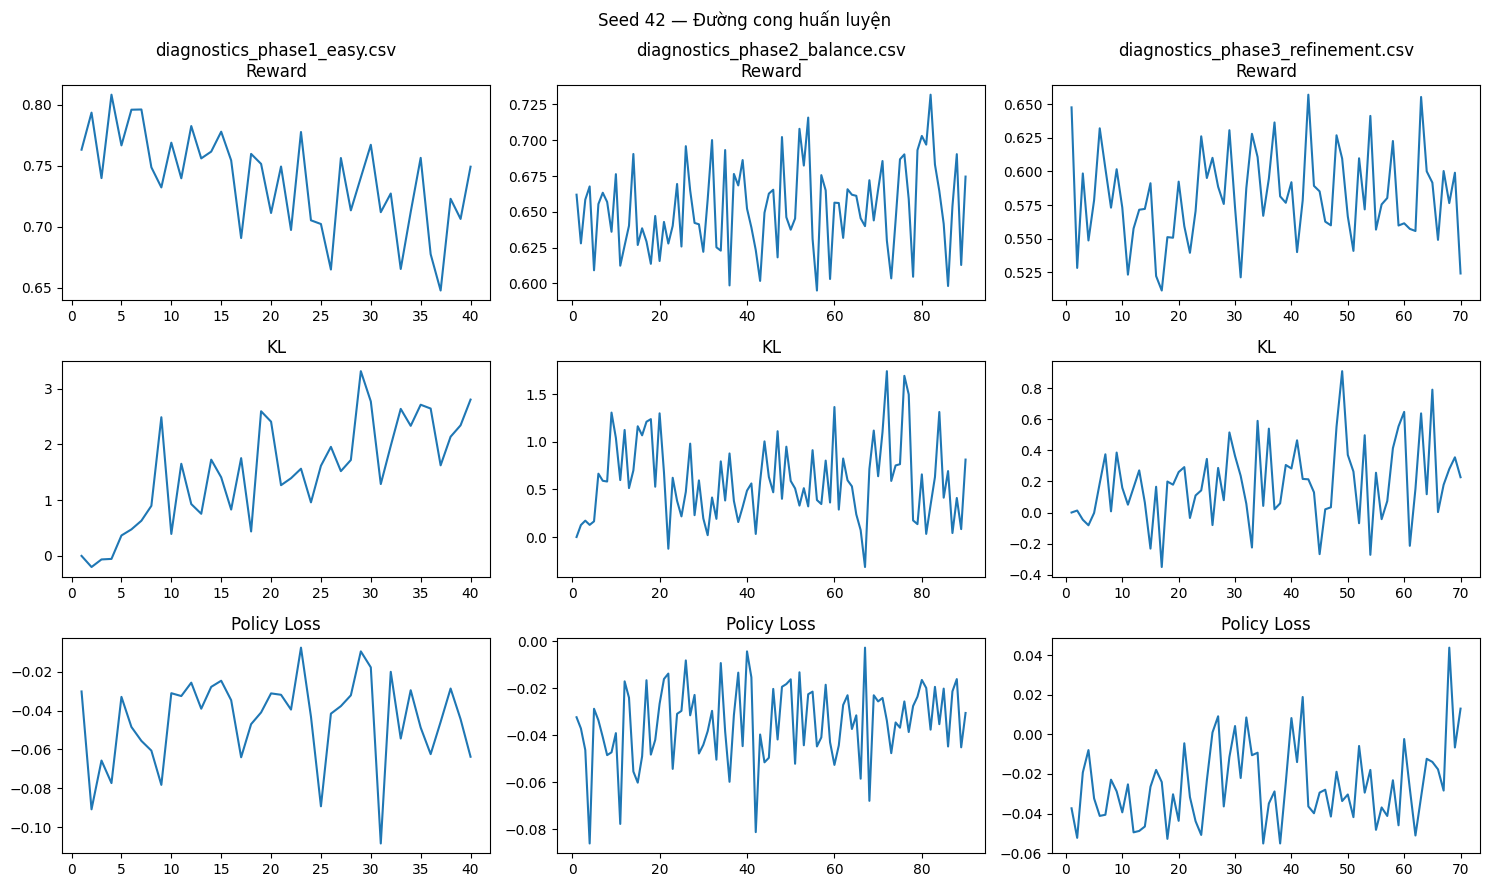

Diagnostics: KL divergence spike / sudden reward drop -> instability (lower LR or increase BETA_KL).
           All 3 curves are smooth without high gains -> genuine empirical variance, preserved as is.


In [22]:
SEED = 42
seed_dir = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
phase_diag_files = ['diagnostics_phase1_easy.csv', 'diagnostics_phase2_balance.csv', 'diagnostics_phase3_refinement.csv']

fig, axes = plt.subplots(3, 3, figsize=(15, 9))
fig.suptitle(f'Seed {SEED} — Training Curves')
for col, fname in enumerate(phase_diag_files):
    path = os.path.join(seed_dir, fname)
    if not os.path.exists(path):
        continue
    df = pd.read_csv(path)
    axes[0, col].plot(df['step'], df['mean_reward']); axes[0, col].set_title(f'{fname}\nReward')
    axes[1, col].plot(df['step'], df['kl']); axes[1, col].set_title('KL')
    axes[2, col].plot(df['step'], df['policy_loss']); axes[2, col].set_title('Policy Loss')
plt.tight_layout()
plt.savefig(f'/content/seed{SEED}_diagnostics.png')
plt.show()
print('Diagnostics: KL spike / reward drop mid-run -> instability (lower LR / increase BETA_KL).')
print('           All 3 curves smooth without large gains -> genuine variance, preserved as is.')

### [Seed 123] Learning Curves: Reward, KL Divergence, and Policy Loss

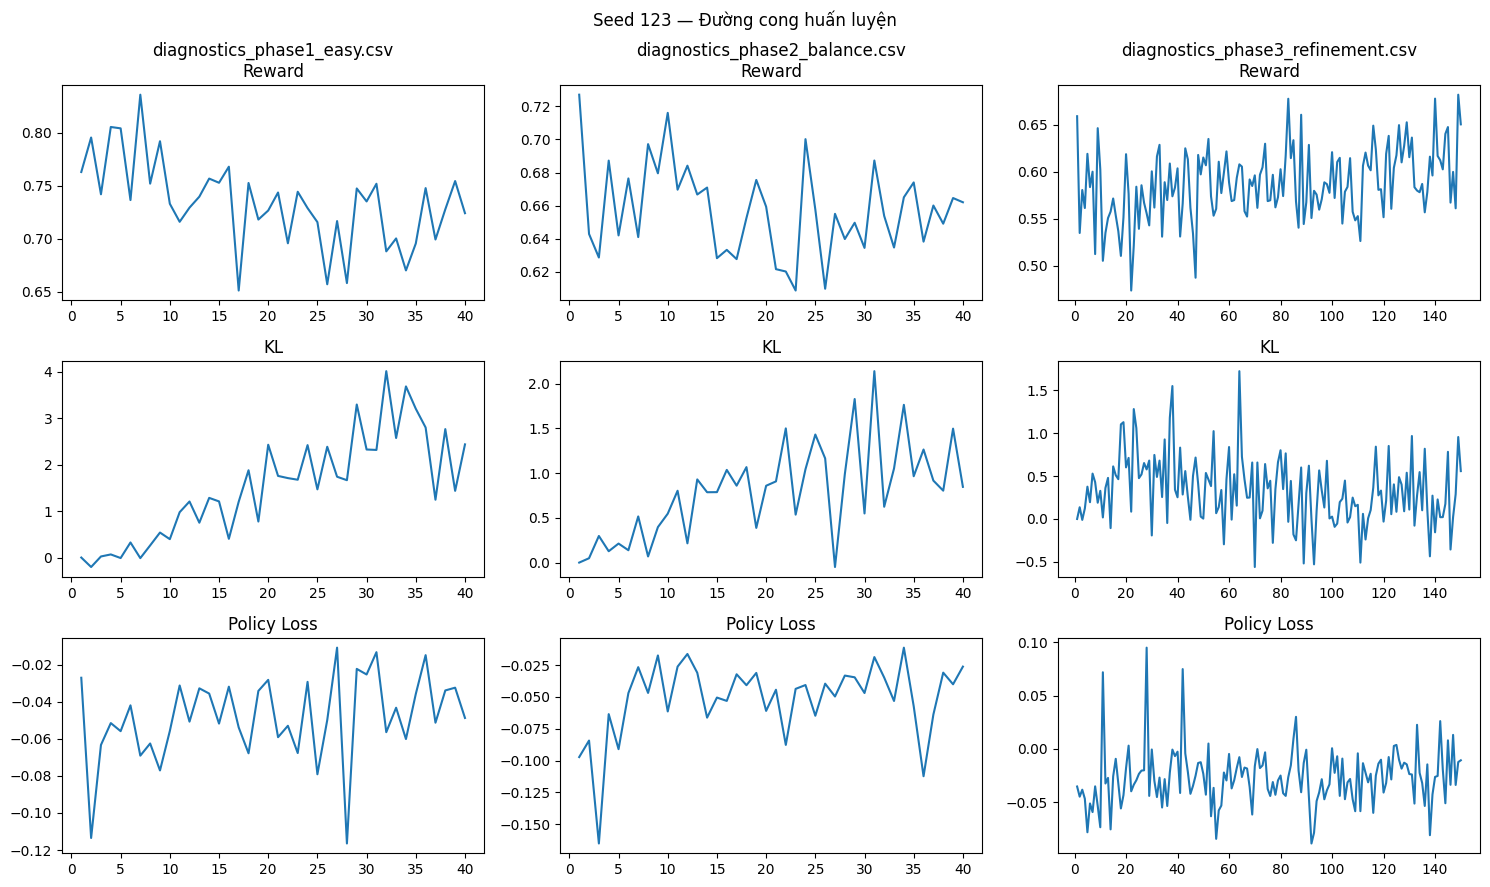

Diagnostics: KL divergence spike / sudden reward drop -> instability (lower LR or increase BETA_KL).
           All 3 curves are smooth without high gains -> genuine empirical variance, preserved as is.


In [23]:
SEED = 123
seed_dir = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
phase_diag_files = ['diagnostics_phase1_easy.csv', 'diagnostics_phase2_balance.csv', 'diagnostics_phase3_refinement.csv']

fig, axes = plt.subplots(3, 3, figsize=(15, 9))
fig.suptitle(f'Seed {SEED} — Training Curves')
for col, fname in enumerate(phase_diag_files):
    path = os.path.join(seed_dir, fname)
    if not os.path.exists(path):
        continue
    df = pd.read_csv(path)
    axes[0, col].plot(df['step'], df['mean_reward']); axes[0, col].set_title(f'{fname}\nReward')
    axes[1, col].plot(df['step'], df['kl']); axes[1, col].set_title('KL')
    axes[2, col].plot(df['step'], df['policy_loss']); axes[2, col].set_title('Policy Loss')
plt.tight_layout()
plt.savefig(f'/content/seed{SEED}_diagnostics.png')
plt.show()
print('Diagnostics: KL spike / reward drop mid-run -> instability (lower LR / increase BETA_KL).')
print('           All 3 curves smooth without large gains -> genuine variance, preserved as is.')

### [Seed 777] Learning Curves: Reward, KL Divergence, and Policy Loss

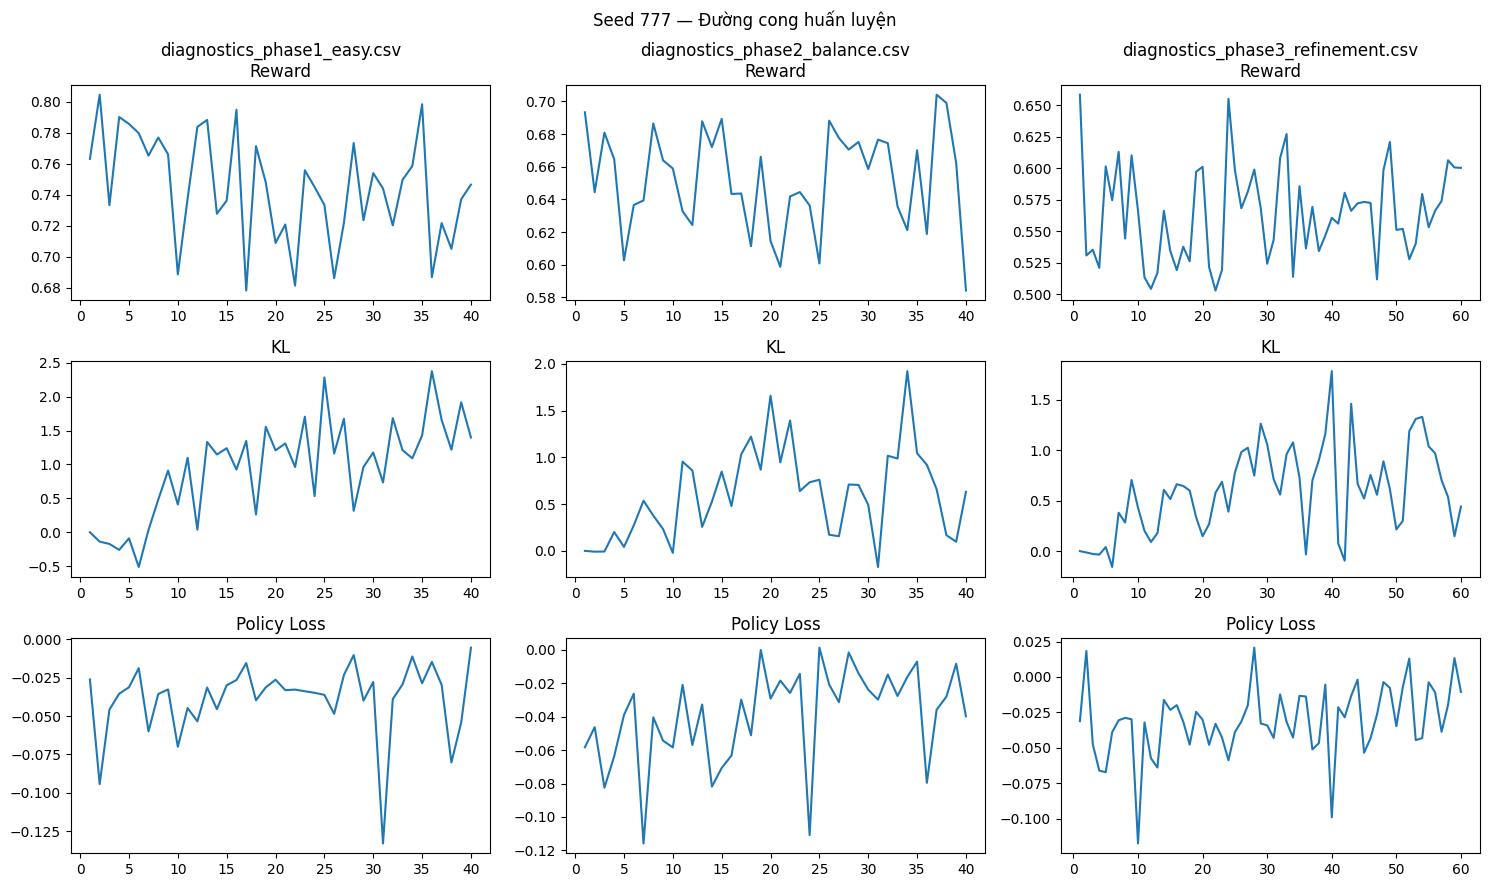

Diagnostics: KL divergence spike / sudden reward drop -> instability (lower LR or increase BETA_KL).
           All 3 curves are smooth without high gains -> genuine empirical variance, preserved as is.


In [24]:
SEED = 777
seed_dir = os.path.join(RL_OUTPUT_DIR, f'seed_{SEED}')
phase_diag_files = ['diagnostics_phase1_easy.csv', 'diagnostics_phase2_balance.csv', 'diagnostics_phase3_refinement.csv']

fig, axes = plt.subplots(3, 3, figsize=(15, 9))
fig.suptitle(f'Seed {SEED} — Training Curves')
for col, fname in enumerate(phase_diag_files):
    path = os.path.join(seed_dir, fname)
    if not os.path.exists(path):
        continue
    df = pd.read_csv(path)
    axes[0, col].plot(df['step'], df['mean_reward']); axes[0, col].set_title(f'{fname}\nReward')
    axes[1, col].plot(df['step'], df['kl']); axes[1, col].set_title('KL')
    axes[2, col].plot(df['step'], df['policy_loss']); axes[2, col].set_title('Policy Loss')
plt.tight_layout()
plt.savefig(f'/content/seed{SEED}_diagnostics.png')
plt.show()
print('Diagnostics: KL spike / reward drop mid-run -> instability (lower LR / increase BETA_KL).')
print('           All 3 curves smooth without large gains -> genuine variance, preserved as is.')

### [Seed 42] Memory-Optimized Sequential Checkpoint Evaluation

In [25]:
# Seed 42: input is original Phase 3 CSV (read-only), model only generates on FAIL.
# Unlike legacy: does not regenerate attempt 1 and does not overwrite final_results.
postval_log_seed42 = evaluate_seed(42)


config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: s-nlp/roberta_toxicity_classifier
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

[transformers] T5ForConditionalGeneration LOAD REPORT from: /content/drive/MyDrive/Data_Khoaluan/ppo_config_f_v1/seed_42/phase3_refinement
Key                   | Status     |  | 
----------------------+------------+--+-
v_head.summary.weight | UNEXPECTED |  | 
v_head.summary.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Seed 42 original/A: n=1312; regen=100.0%; failed_all=100.0%
Seed 42 original/B: n=1312; regen=100.0%; failed_all=100.0%
Seed 42 converted/A: n=1312; regen=88.1%; failed_all=84.3%
Seed 42 converted/B: n=1312; regen=88.1%; failed_all=84.3%


### [Seed 123] Memory-Optimized Sequential Checkpoint Evaluation

In [26]:
# Seed 123: input is original Phase 3 CSV (read-only), model only generates on FAIL.
# Unlike legacy: does not regenerate attempt 1 and does not overwrite final_results.
postval_log_seed123 = evaluate_seed(123)


Loading weights:   0%|          | 0/257 [00:01<?, ?it/s]

[transformers] T5ForConditionalGeneration LOAD REPORT from: /content/drive/MyDrive/Data_Khoaluan/ppo_config_f_v1/seed_123/phase3_refinement
Key                   | Status     |  | 
----------------------+------------+--+-
v_head.summary.weight | UNEXPECTED |  | 
v_head.summary.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Seed 123 original/A: n=1312; regen=100.0%; failed_all=100.0%
Seed 123 original/B: n=1312; regen=100.0%; failed_all=100.0%
Seed 123 converted/A: n=1312; regen=89.6%; failed_all=86.6%
Seed 123 converted/B: n=1312; regen=89.6%; failed_all=86.6%


### [Seed 777] Memory-Optimized Sequential Checkpoint Evaluation

In [27]:
# Seed 777: input is original Phase 3 CSV (read-only), model only generates on FAIL.
# Unlike legacy: does not regenerate attempt 1 and does not overwrite final_results.
postval_log_seed777 = evaluate_seed(777)


Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

[transformers] T5ForConditionalGeneration LOAD REPORT from: /content/drive/MyDrive/Data_Khoaluan/ppo_config_f_v1/seed_777/phase3_refinement
Key                   | Status     |  | 
----------------------+------------+--+-
v_head.summary.weight | UNEXPECTED |  | 
v_head.summary.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Seed 777 original/A: n=1312; regen=100.0%; failed_all=100.0%
Seed 777 original/B: n=1312; regen=100.0%; failed_all=100.0%
Seed 777 converted/A: n=1312; regen=89.9%; failed_all=88.0%
Seed 777 converted/B: n=1312; regen=89.9%; failed_all=88.0%


In [28]:
# Cell 50A — unified function to build Table 3/4 and Post-Val diagnostics.
def get_variant_frame(seed, rule, fallback):
    p=os.path.join(NEW_RESULTS_DIR,f'{rule}_fallback_{fallback}',
                   f'per_sample_seed{seed}_phase3_postval.csv')
    assert os.path.isfile(p), f'Seed {seed} not yet evaluated: {p}'
    return pd.read_csv(p,keep_default_na=False)

def get_original_frame(seed, phase):
    p=os.path.join(RESULTS_DIR,f'per_sample_seed{seed}_{phase}.csv')
    assert os.path.isfile(p), f'Missing original phase results (read-only): {p}'
    df=pd.read_csv(p,keep_default_na=False)
    if 'STA (indep.)' not in df:
        # Do not modify original CSV; append directly to in-memory DataFrame.
        df['STA (indep.)']=compute_sta_indep(df['Y'].astype(str).tolist())
    return df

def build_tables(seed):
    sft=pd.read_csv(os.path.join(RESULTS_DIR,'baseline_per_sample.csv'),keep_default_na=False)
    if 'STA (indep.)' not in sft:
        sft['STA (indep.)']=compute_sta_indep(sft['Y'].astype(str).tolist())
    data={'Baseline (SFT)':sft}
    for label,phase in [('Phase 1 (Easy)','phase1_easy'),
                        ('Phase 2 (+Med)','phase2_balance'),
                        ('Phase 3 (Full)','phase3_refinement')]:
        data[label]=get_original_frame(seed,phase)
    for rule in FLU_THRESHOLDS:
        for fb in ('A','B'):
            data[f'Post-Val {rule} fallback {fb}']=get_variant_frame(seed,rule,fb)
    for prefix,label in [('table3',None),('table3b','toxic'),('table3c','nontoxic')]:
        rows=[]
        base=data['Baseline (SFT)']
        b=base if label is None else base[base['label']==label]
        base_score=summarize(b)
        for phase,df in data.items():
            sub=df if label is None else df[df['label']==label]
            vals=summarize(sub)
            row={'Phase':phase,'Count':len(sub),**vals}
            for m in ('STA','STA (indep.)','Sim','Flu','Joint'):
                if m in vals and m in base_score:
                    row[f'Gain_{m}']=vals[m]-base_score[m]
            rows.append(row)
        pd.DataFrame(rows).to_csv(os.path.join(NEW_RESULTS_DIR,'summary',
                             f'{prefix}_seed{seed}.csv'),index=False)
    # Original Table 4 only evaluates Phase 3, without mixing Post-Val by-band into original table.
    phase3=data['Phase 3 (Full)']
    for prefix,label in [('table4',None),('table4b','toxic'),('table4c','nontoxic')]:
        rows=[]
        for band in ['easy','medium','hard','overall']:
            sub=phase3 if band=='overall' else phase3[phase3['band']==band]
            if label is not None: sub=sub[sub['label']==label]
            rows.append({'Difficulty':band.capitalize(),'Count':len(sub),**summarize(sub)})
        pd.DataFrame(rows).to_csv(os.path.join(NEW_RESULTS_DIR,'summary',
                              f'{prefix}_seed{seed}.csv'),index=False)
    return data

def postval_diagnostics():
    summaries=[]; first_rows=[]; attempt_rows=[]
    for seed in SEED_LIST:
        path=os.path.join(NEW_RESULTS_DIR,'attempts',f'attempts_seed{seed}.csv')
        assert os.path.isfile(path),path
        log=pd.read_csv(path,keep_default_na=False)
        for rule,t in FLU_THRESHOLDS.items():
            marks=annotate_attempts(log,t)
            n=marks['idx'].nunique()
            first=marks[marks['attempt']==1]
            assert len(first)==n
            choice=get_variant_frame(seed,rule,'A')
            assert len(choice)==n
            summaries.append({'seed':seed,'threshold_rule':rule,'n':n,
                 'regeneration_rate':float(choice['regenerated'].mean()),
                 'avg_attempts':float(choice['n_attempts'].mean()),
                 'failed_all_rate':float(choice['failed_all'].mean()),
                 'accepted_rate':float(choice['accepted'].mean()),
                 'manual_review_rate_B':float(get_variant_frame(seed,rule,'B')['manual_review'].mean())})
            first_rows.append({'seed':seed,'threshold_rule':rule,'n':n,**
                   {c+'_rate':float(first[c].mean()) for c in
                    ['fail_toxicity','fail_semantic','fail_fluency','fail_length',
                     'fail_short','fail_long','fail_any']}})
            for attempt in (1,2,3):
                # Only consider indices that ACTUALLY reached this attempt per rule.
                reach=[]
                for idx,g in marks.groupby('idx',sort=False):
                    d=g.sort_values('attempt')
                    if attempt==1 or (len(d[d['attempt']<attempt])==attempt-1 and
                        d[d['attempt']<attempt]['fail_any'].all()):
                        z=d[d['attempt']==attempt]
                        if len(z):reach.append(z.iloc[0])
                if not reach:continue
                z=pd.DataFrame(reach)
                attempt_rows.append({'seed':seed,'threshold_rule':rule,'attempt':attempt,
                   'temp':'beam4' if attempt==1 else TEMPERATURES[attempt],
                   'n_reached':len(z),'fail_short_rate':float(z['fail_short'].mean()),
                   'fail_long_rate':float(z['fail_long'].mean()),
                   'fail_length_rate':float(z['fail_length'].mean())})
    base=os.path.join(NEW_RESULTS_DIR,'diagnostics')
    pd.DataFrame(summaries).to_csv(os.path.join(base,'regeneration_by_seed.csv'),index=False)
    pd.DataFrame(first_rows).to_csv(os.path.join(base,'first_attempt_failures.csv'),index=False)
    pd.DataFrame(attempt_rows).to_csv(os.path.join(base,'length_diagnostics_by_attempt.csv'),index=False)
    print(pd.DataFrame(summaries).to_string(index=False))
    return pd.DataFrame(summaries)

In [29]:
# Cell 50B — SFT reference on SAME toxic-only subset, no generation, no regeneration.
sft_path=os.path.join(RESULTS_DIR,'baseline_per_sample.csv')
assert os.path.isfile(sft_path)
sft_df=pd.read_csv(sft_path,keep_default_na=False)
assert sft_df['X'].astype(str).tolist()==test_toxic['text'].astype(str).tolist()
sft_scored=score_outputs(sft_df['X'].tolist(),sft_df['Y'].tolist(),
                         sft_df['label'].tolist(),sft_df['band'].tolist())
rows=[]
for rule,threshold in FLU_THRESHOLDS.items():
    for subset_name,subset in [('toxic_only',sft_scored[sft_scored['label']=='toxic']),
                                ('full',sft_scored)]:
        d=pd.DataFrame({'tox':subset['tox'],'sem':subset['Sim'],
                        'flu':subset['Flu'],'ratio':subset['ratio']})
        marked=annotate_attempts(d,threshold)
        rows.append({'rule':rule,'subset':subset_name,'n':len(marked),**
                     {c+'_rate':float(marked[c].mean()) for c in
                      ['fail_toxicity','fail_semantic','fail_fluency','fail_length',
                       'fail_short','fail_long','fail_any']}})
pd.DataFrame(rows).to_csv(os.path.join(NEW_RESULTS_DIR,'diagnostics',
                                      'sft_postval_diagnostics.csv'),index=False)
print(pd.DataFrame(rows).to_string(index=False))

     rule     subset    n  fail_toxicity_rate  fail_semantic_rate  fail_fluency_rate  fail_length_rate  fail_short_rate  fail_long_rate  fail_any_rate
 original toxic_only 1150            0.168696                 0.0           1.000000          0.257391         0.257391             0.0       1.000000
 original       full 1312            0.163110                 0.0           1.000000          0.235518         0.235518             0.0       1.000000
converted toxic_only 1150            0.168696                 0.0           0.140000          0.257391         0.257391             0.0       0.466957
converted       full 1312            0.163110                 0.0           0.145579          0.235518         0.235518             0.0       0.450457


### [Seed 42] Metric Aggregation: Full, Toxic, and Non-toxic Subsets

In [30]:
tables_seed42 = build_tables(42)


In [31]:
# Original Cell 53 computed redundant Gain file: merged into build_tables(42).
print('Seed 42: Gain already exists in table3*_seed42.csv (NEW_RESULTS_DIR).')

Seed 42: Gain already exists in table3*_seed42.csv (NEW_RESULTS_DIR).


### [Seed 123] Metric Aggregation: Full, Toxic, and Non-toxic Subsets

In [32]:
tables_seed123 = build_tables(123)


In [33]:
# Original Cell 56 computed redundant Gain file: merged into build_tables(123).
print('Seed 123: Gain already exists in table3*_seed123.csv (NEW_RESULTS_DIR).')

Seed 123: Gain already exists in table3*_seed123.csv (NEW_RESULTS_DIR).


### [Seed 777] Metric Aggregation: Full, Toxic, and Non-toxic Subsets

In [34]:
tables_seed777 = build_tables(777)


In [35]:
# Original Cell 59 computed redundant Gain file: merged into build_tables(777).
print('Seed 777: Gain already exists in table3*_seed777.csv (NEW_RESULTS_DIR).')

Seed 777: Gain already exists in table3*_seed777.csv (NEW_RESULTS_DIR).


## Main Summary Table: Per-Seed Results and Mean ± Std

**Official benchmark summary table for reporting** — reports all individual seeds, not just the mean.

In [36]:

def print_new_summary(prefix):
    frames=[]
    for seed in SEED_LIST:
        p=os.path.join(NEW_RESULTS_DIR,'summary',f'{prefix}_seed{seed}.csv')
        if not os.path.isfile(p): raise FileNotFoundError(p)
        d=pd.read_csv(p)
        d['seed']=seed
        frames.append(d)
    whole=pd.concat(frames,ignore_index=True)
    key='Phase' if prefix.startswith('table3') else 'Difficulty'
    metric_cols=[m for m in ['STA','STA (indep.)','Sim','Flu','Joint'] if m in whole.columns]
    summ=whole.groupby(key,sort=False)[metric_cols].agg(['mean','std'])
    summ.columns=[f'{m}_{agg}' for m,agg in summ.columns]
    summ.reset_index().to_csv(os.path.join(NEW_RESULTS_DIR,'summary',f'{prefix}_mean_std.csv'),index=False)
    print(prefix, '\n',summ.round(4).to_string())
for prefix in ['table3','table3b','table3c','table4','table4b','table4c']:
    print_new_summary(prefix)


table3 
                                STA_mean  STA_std  STA (indep.)_mean  STA (indep.)_std  Sim_mean  Sim_std  Flu_mean  Flu_std  Joint_mean  Joint_std
Phase                                                                                                                                             
Baseline (SFT)                   0.8674   0.0000             0.9033            0.0000    0.9718   0.0000    0.5484   0.0000      0.7588     0.0000
Phase 1 (Easy)                   0.8784   0.0065             0.9109            0.0045    0.9366   0.0130    0.5392   0.0034      0.7480     0.0066
Phase 2 (+Med)                   0.8904   0.0107             0.9180            0.0100    0.9111   0.0059    0.5327   0.0028      0.7417     0.0045
Phase 3 (Full)                   0.8988   0.0053             0.9272            0.0054    0.9029   0.0041    0.5273   0.0067      0.7403     0.0059
Post-Val original fallback A     0.9414   0.0063             0.9643            0.0053    0.8332   0.0220    0

## Appendix: Bootstrap Confidence Intervals (95% CI)

Inter-seed variance is reported via empirical Mean ± Std across seeds — using Bootstrap CI as primary would obscure true variance. The PRIMARY table remains the section above (individual seeds + Mean ± Std).

In [37]:

# Bootstrap CI (appendix) on NEW results, does not write to legacy final_results.
def bootstrap_ci(values, n_boot=1000, ci=0.95, seed=42):
    vals=np.asarray(values,dtype=float)
    if not len(vals): return (float('nan'),)*3
    rng=np.random.default_rng(seed)
    boot=np.array([rng.choice(vals,len(vals),replace=True).mean() for _ in range(n_boot)])
    a=(1-ci)/2*100
    return float(vals.mean()),float(np.percentile(boot,a)),float(np.percentile(boot,100-a))

ci_rows=[]
for seed in SEED_LIST:
    for rule in FLU_THRESHOLDS:
        for fallback in ('A','B'):
            df=get_variant_frame(seed,rule,fallback)
            for scope,label in [('full',None),('toxic_only','toxic'),('nontoxic','nontoxic')]:
                sub=df if label is None else df[df.label==label]
                for metric in ['STA','STA (indep.)','Sim','Flu','Joint']:
                    v,lo,hi=bootstrap_ci(sub[metric],seed=seed)
                    ci_rows.append({'seed':seed,'rule':rule,'fallback':fallback,'scope':scope,
                                    'metric':metric,'n':len(sub),'mean':v,'CI_low':lo,'CI_high':hi})
pd.DataFrame(ci_rows).to_csv(os.path.join(NEW_RESULTS_DIR,'summary','bootstrap_ci_new.csv'),index=False)


In [38]:
# N4 original overwrote final_results/*.csv. Replaced with STA (indep.) in score_outputs().
# No legacy source overwrite. All new tables include STA (indep.) from build_tables().
print('N4: independent scoring in score_outputs/get_original_frame; final_results preserved.')


N4: independent scoring in score_outputs/get_original_frame; final_results preserved.


## Behavioral Metrics (Levenshtein Distance, Length Ratio) & Perplexity

In [39]:

# Behavior functions from original Config F — definition only, no source files written.
def tokenize_simple(text): return str(text).lower().split()
def levenshtein_token(a,b):
    n,m=len(a),len(b)
    dp=[[0]*(m+1) for _ in range(n+1)]
    for i in range(n+1):dp[i][0]=i
    for j in range(m+1):dp[0][j]=j
    for i in range(1,n+1):
        for j in range(1,m+1):
            dp[i][j]=dp[i-1][j-1] if a[i-1]==b[j-1] else 1+min(dp[i-1][j],dp[i][j-1],dp[i-1][j-1])
    return dp[n][m]
def compute_edit_behavior(row):
    x,y=str(row['X']).strip(),str(row['Y']).strip()
    xt,yt=tokenize_simple(x),tokenize_simple(y)
    xl=max(len(xt),1); yl=len(yt)
    return pd.Series({'unchanged':x.lower()==y.lower(),
                     'token_edit_rate':levenshtein_token(xt,yt)/xl,
                     'truncated':yl<xl,'clause_loss':((xl-yl)/xl)>0.30})


In [40]:
# ==============================================================================
# Cell 70 — COMPREHENSIVE 11 METRICS CALCULATION ACROSS ALL SLICES (PHASE, BAND, POSTVAL, SEED)
# ==============================================================================
MASTER_DIR = os.path.join(NEW_RESULTS_DIR, 'master_tables')
os.makedirs(MASTER_DIR, exist_ok=True)

def compute_comprehensive_metrics(df):
    if df is None or len(df) == 0:
        return {}
    sta = float(df['STA'].mean()) if 'STA' in df else np.nan
    sta_indep = float(df['STA (indep.)'].mean()) if 'STA (indep.)' in df else np.nan
    sim = float(df['Sim'].mean()) if 'Sim' in df else np.nan
    flu = float(df['Flu'].mean()) if 'Flu' in df else np.nan
    joint = float(df['Joint'].mean()) if 'Joint' in df else np.nan

    if 'ratio' in df:
        ratios = df['ratio'].astype(float)
    else:
        ratios = pd.Series([len(str(y).split()) / max(len(str(x).split()), 1) for x, y in zip(df['X'], df['Y'])])
    # Specific metrics: SLR = fraction of outputs too short; Mean Length Ratio = mean(|Y|/|X|).
    slr_mean = float((ratios < 0.70).mean())
    slr_std = float((ratios < 0.70).astype(float).std(ddof=1)) if len(ratios) > 1 else 0.0
    mean_length_ratio = float(ratios.mean())
    mean_length_ratio_std = float(ratios.std(ddof=1)) if len(ratios) > 1 else 0.0

    beh = df.apply(compute_edit_behavior, axis=1)
    truncated_rate = float(beh['truncated'].mean()) * 100.0
    token_edit_rate = float(beh['token_edit_rate'].mean())
    unchanged_rate = float(beh['unchanged'].mean()) * 100.0

    if 'PPL' in df:
        ppls = df['PPL'].astype(float)
    else:
        ppls = pd.Series([compute_perplexity(str(y)) for y in df['Y']])
    ppl_median = float(ppls.median())
    q1, q3 = ppls.quantile([0.25, 0.75]).tolist()
    ppl_iqr = float(q3 - q1)
    pct_20_150 = float(((ppls >= 20) & (ppls <= 150)).mean()) * 100.0

    return {
        'STA': sta, 'STA_indep': sta_indep, 'Sim': sim, 'Flu': flu, 'Joint': joint,
        'SLR': slr_mean, 'SLR_std': slr_std,
        'Mean_Length_Ratio': mean_length_ratio, 'Mean_Length_Ratio_std': mean_length_ratio_std,
        'truncated': truncated_rate, 'token_edit_rate': token_edit_rate, 'unchanged': unchanged_rate,
        'median_PPL': ppl_median, 'IQR_PPL': ppl_iqr, 'pct_in_20_150': pct_20_150
    }

# Collect detailed metrics for each seed
records_by_phase = []
records_by_band = []
behavior_rows = []
ppl_rows = []

for seed in SEED_LIST:
    groups = {'SFT': pd.read_csv(os.path.join(RESULTS_DIR, 'baseline_per_sample.csv'), keep_default_na=False)}
    if 'STA (indep.)' not in groups['SFT']:
        groups['SFT']['STA (indep.)'] = compute_sta_indep(groups['SFT']['Y'].astype(str).tolist())
    if 'ratio' not in groups['SFT']:
        groups['SFT']['ratio'] = [len(str(y).split()) / max(len(str(x).split()), 1) for x, y in zip(groups['SFT']['X'], groups['SFT']['Y'])]

    for p in ['phase1_easy', 'phase2_balance', 'phase3_refinement']:
        groups[p] = get_original_frame(seed, p)
        if 'ratio' not in groups[p]:
            groups[p]['ratio'] = [len(str(y).split()) / max(len(str(x).split()), 1) for x, y in zip(groups[p]['X'], groups[p]['Y'])]

    for rule in FLU_THRESHOLDS:
        for fallback in ('A', 'B'):
            groups[f'postval_{rule}_{fallback}'] = get_variant_frame(seed, rule, fallback)
            if 'ratio' not in groups[f'postval_{rule}_{fallback}']:
                groups[f'postval_{rule}_{fallback}']['ratio'] = [len(str(y).split()) / max(len(str(x).split()), 1) for x, y in zip(groups[f'postval_{rule}_{fallback}']['X'], groups[f'postval_{rule}_{fallback}']['Y'])]

    # 1. Collect for Phase Table & Main Table (toxic_only)
    for phase_name, df in groups.items():
        sub_tox = df[df['label'] == 'toxic']
        m_tox = compute_comprehensive_metrics(sub_tox)
        records_by_phase.append({'seed': seed, 'phase': phase_name, 'n': len(sub_tox), **m_tox})

        # Save legacy format for full backward compatibility
        for scope, sub in [('full', df), ('toxic_only', sub_tox)]:
            if not len(sub): continue
            e = sub.apply(compute_edit_behavior, axis=1)
            behavior_rows.append({'seed': seed, 'phase': phase_name, 'scope': scope, 'n': len(sub),
                                  **{k+'_rate': float(e[k].mean()) for k in e.columns}})
            ppls = pd.Series(sub['PPL'].astype(float).to_numpy()) if 'PPL' in sub.columns else pd.Series([compute_perplexity(str(y)) for y in sub['Y']])
            q1, q3 = ppls.quantile([0.25, 0.75]).tolist()
            ppl_rows.append({'seed': seed, 'phase': phase_name, 'scope': scope, 'n': len(sub),
                             'mean_PPL': float(ppls.mean()), 'median_PPL': float(ppls.median()),
                             'Q1': float(q1), 'Q3': float(q3), 'IQR': float(q3-q1),
                             'pct_in_20_150': float(((ppls>=20)&(ppls<=150)).mean())})

    # 2. Collect for Band Table (Easy, Medium, Hard for Phase 3 and SFT)
    phase3 = groups['phase3_refinement']
    for band in ['easy', 'medium', 'hard', 'overall']:
        sub = phase3[phase3['label'] == 'toxic']
        if band != 'overall': sub = sub[sub['band'] == band]
        m_band = compute_comprehensive_metrics(sub)
        records_by_band.append({'seed': seed, 'model': 'Phase 3 (Full)', 'band': band.capitalize(), 'n': len(sub), **m_band})

        # Post-val converted fallback B by band (for comparison if needed)
        pv_b = groups.get('postval_converted_B', None)
        if pv_b is not None:
            sub_pv = pv_b[pv_b['label'] == 'toxic']
            if band != 'overall': sub_pv = sub_pv[sub_pv['band'] == band]
            m_pv = compute_comprehensive_metrics(sub_pv)
            records_by_band.append({'seed': seed, 'model': 'Post-Val (Converted, b)', 'band': band.capitalize(), 'n': len(sub_pv), **m_pv})

# Save intermediate summary files
pd.DataFrame(behavior_rows).to_csv(os.path.join(NEW_RESULTS_DIR, 'summary', 'editing_behavior.csv'), index=False)
pd.DataFrame(ppl_rows).to_csv(os.path.join(NEW_RESULTS_DIR, 'ppl', 'ppl_by_seed.csv'), index=False)
pd.DataFrame(records_by_phase).to_csv(os.path.join(MASTER_DIR, 'raw_metrics_by_phase_seeds.csv'), index=False)
pd.DataFrame(records_by_band).to_csv(os.path.join(MASTER_DIR, 'raw_metrics_by_band_seeds.csv'), index=False)
print("Completed comprehensive metrics calculation (including SLR and Mean Length Ratio) across all Phase, Band, and Post-Val variants.")

Completed comprehensive metrics calculation (including SLR and Mean Length Ratio) across all Phase, Band, and Post-Val variants.


In [41]:
# ==============================================================================
# Cell 71 — EXPORT ALL 4 MASTER TABLE GROUPS (MEAN ± STD) & SAVE MASTER_REPORT.MD
# ==============================================================================
def agg_mean_std_display(df_raw, group_col):
    metrics = ['STA', 'STA_indep', 'Sim', 'Flu', 'Joint', 'SLR', 'Mean_Length_Ratio', 'truncated', 'token_edit_rate', 'unchanged', 'median_PPL', 'IQR_PPL', 'pct_in_20_150']
    res = []
    for grp, g in df_raw.groupby(group_col, sort=False):
        row = {group_col: grp, 'N_seeds': len(g)}
        for m in metrics:
            vals = g[m].dropna()
            mean_val = float(vals.mean())
            std_val = float(vals.std(ddof=1)) if len(vals) > 1 else 0.0
            row[f'{m}_mean'] = mean_val
            row[f'{m}_std'] = std_val
            if m in ['truncated', 'unchanged', 'pct_in_20_150']:
                row[m] = f"{mean_val:.2f} ± {std_val:.2f}%"
            elif m in ['median_PPL', 'IQR_PPL']:
                row[m] = f"{mean_val:.1f} ± {std_val:.1f}"
            else:
                row[m] = f"{mean_val:.4f} ± {std_val:.4f}"
        res.append(row)
    return pd.DataFrame(res)

df_phase_raw = pd.read_csv(os.path.join(MASTER_DIR, 'raw_metrics_by_phase_seeds.csv'))
df_band_raw = pd.read_csv(os.path.join(MASTER_DIR, 'raw_metrics_by_band_seeds.csv'))

# ------------------------------------------------------------------------------
# GROUP 1: MAIN TABLE (Phase 3, toxic-only, Mean ± Std across seeds)
# ------------------------------------------------------------------------------
main_target_phases = [
    ('SFT', 'Baseline (SFT)'),
    ('phase3_refinement', 'TRIAD Phase 3 (Full)'),
    ('postval_converted_A', 'TRIAD + Post-Val (Converted, Keep Attempt 3 [a])'),
    ('postval_converted_B', 'TRIAD + Post-Val (Converted, Keep Attempt 1 [b])'),
    ('postval_original_A', 'TRIAD + Post-Val (Original, Keep Attempt 3 [a])'),
    ('postval_original_B', 'TRIAD + Post-Val (Original, Keep Attempt 1 [b])')
]
sub_main = df_phase_raw[df_phase_raw['phase'].isin([p[0] for p in main_target_phases])].copy()
name_map = dict(main_target_phases)
sub_main['Method'] = sub_main['phase'].map(name_map)
table_1_master = agg_mean_std_display(sub_main, 'Method')

# Format column display order cleanly
disp_cols = ['Method', 'STA', 'STA_indep', 'Sim', 'Flu', 'Joint', 'SLR', 'Mean_Length_Ratio', 'truncated', 'token_edit_rate', 'unchanged', 'median_PPL', 'IQR_PPL', 'pct_in_20_150']
disp_rename = {
    'Method': 'Method', 'STA': 'STA', 'STA_indep': 'STA (indep.)', 'Sim': 'Sim', 'Flu': 'Flu', 'Joint': 'Joint',
    'SLR': 'SLR (<0.70)', 'Mean_Length_Ratio': 'Mean Length Ratio', 'truncated': 'Short-fail Rate (%)', 'token_edit_rate': 'Token Edit Rate', 'unchanged': 'Unchanged Rate (%)',
    'median_PPL': 'PPL Median', 'IQR_PPL': 'PPL IQR', 'pct_in_20_150': '% PPL [20,150]'
}
t1_display = table_1_master[disp_cols].rename(columns=disp_rename)
t1_display.to_csv(os.path.join(MASTER_DIR, 'master_table_1_phase3_toxic_only.csv'), index=False)
table_1_master.to_csv(os.path.join(MASTER_DIR, 'master_table_1_full_numeric.csv'), index=False)

# ------------------------------------------------------------------------------
# GROUP 2: BY BAND (Easy, Medium, Hard, Overall for Phase 3 toxic-only)
# ------------------------------------------------------------------------------
sub_band_p3 = df_band_raw[df_band_raw['model'] == 'Phase 3 (Full)'].copy()
table_2_master = agg_mean_std_display(sub_band_p3, 'band')
t2_display = table_2_master[['band'] + disp_cols[1:]].rename(columns={'band': 'Difficulty Band', **disp_rename})
t2_display.to_csv(os.path.join(MASTER_DIR, 'master_table_2_by_band.csv'), index=False)
table_2_master.to_csv(os.path.join(MASTER_DIR, 'master_table_2_full_numeric.csv'), index=False)

# ------------------------------------------------------------------------------
# GROUP 3: BY PHASE (Phase 1, 2, 3, SFT for toxic-only)
# ------------------------------------------------------------------------------
phase_target_seq = [
    ('SFT', 'Baseline (SFT)'),
    ('phase1_easy', 'Phase 1 (Easy)'),
    ('phase2_balance', 'Phase 2 (+Med)'),
    ('phase3_refinement', 'Phase 3 (Full)')
]
sub_phase_prog = df_phase_raw[df_phase_raw['phase'].isin([p[0] for p in phase_target_seq])].copy()
sub_phase_prog['Phase_Name'] = sub_phase_prog['phase'].map(dict(phase_target_seq))
table_3_master = agg_mean_std_display(sub_phase_prog, 'Phase_Name')
t3_display = table_3_master[['Phase_Name'] + disp_cols[1:]].rename(columns={'Phase_Name': 'Phase', **disp_rename})
t3_display.to_csv(os.path.join(MASTER_DIR, 'master_table_3_by_phase.csv'), index=False)
table_3_master.to_csv(os.path.join(MASTER_DIR, 'master_table_3_full_numeric.csv'), index=False)

# ------------------------------------------------------------------------------
# GROUP 4: POST-VAL (Table G attempt 1 fail, Regeneration rate / failed all 3, Comparison a vs b)
# ------------------------------------------------------------------------------
postval_diag_df = postval_diagnostics()

# 4a. Table G: Fail reasons at attempt 1 (Original vs Converted comparison, Mean ± Std)
first_fail_path = os.path.join(NEW_RESULTS_DIR, 'diagnostics', 'first_attempt_failures.csv')
first_df = pd.read_csv(first_fail_path)
t4a_rows = []
for rule in ['original', 'converted']:
    g = first_df[first_df['threshold_rule'] == rule]
    row = {'Rule': 'Original (Flu > 0.70)' if rule == 'original' else f'Converted (Flu > {FLU_THRESHOLDS["converted"]:.4f}, PPL < {TARGET_PPL:.1f})'}
    for col, c_name in [('fail_toxicity_rate', 'Toxicity Fail (>=0.30)'),
                        ('fail_semantic_rate', 'Semantic Fail (<=0.70)'),
                        ('fail_fluency_rate', 'Fluency Fail'),
                        ('fail_length_rate', 'Length Fail (0.7-1.3)'),
                        ('fail_short_rate', 'Of which: Short-fail (<0.7)'),
                        ('fail_long_rate', 'Of which: Long-fail (>1.3)'),
                        ('fail_any_rate', 'Any Fail (Regenerated)')]:
        vals = g[col] * 100.0
        row[c_name] = f"{vals.mean():.2f} ± {vals.std(ddof=1):.2f}%"
        row[f'{col}_mean'] = float(vals.mean())
        row[f'{col}_std'] = float(vals.std(ddof=1))
    t4a_rows.append(row)
table_4a_master = pd.DataFrame(t4a_rows)
table_4a_master.to_csv(os.path.join(MASTER_DIR, 'master_table_4a_first_attempt_tableG.csv'), index=False)

# 4b. Regeneration rate, failed all three attempts (Flagged review)
regen_path = os.path.join(NEW_RESULTS_DIR, 'diagnostics', 'regeneration_by_seed.csv')
regen_df = pd.read_csv(regen_path)
t4b_rows = []
for rule in ['original', 'converted']:
    g = regen_df[regen_df['threshold_rule'] == rule]
    row = {'Rule': 'Original (Flu > 0.70)' if rule == 'original' else f'Converted (Flu > {FLU_THRESHOLDS["converted"]:.4f})'}
    for col, c_name in [('regeneration_rate', 'Regeneration Rate (%)'),
                        ('failed_all_rate', 'Failed All 3 / Manual Review (%)'),
                        ('avg_attempts', 'Avg Attempts'),
                        ('accepted_rate', 'Accepted Rate (%)')]:
        mul = 100.0 if col != 'avg_attempts' else 1.0
        unit = '%' if col != 'avg_attempts' else ''
        vals = g[col] * mul
        row[c_name] = f"{vals.mean():.2f} ± {vals.std(ddof=1):.2f}{unit}"
    t4b_rows.append(row)
table_4b_master = pd.DataFrame(t4b_rows)
table_4b_master.to_csv(os.path.join(MASTER_DIR, 'master_table_4b_regeneration_stats.csv'), index=False)

# 4c. Post-Val comparison by output retention rule (a) vs (b)
pv_comp = table_1_master[table_1_master['Method'].str.contains('Post-Val')].copy()
t4c_display = pv_comp[disp_cols].rename(columns=disp_rename)
t4c_display.to_csv(os.path.join(MASTER_DIR, 'master_table_4c_fallback_comparison.csv'), index=False)

# Save legacy PPL Mean Std for compatibility
ppl_by_seed = pd.read_csv(os.path.join(NEW_RESULTS_DIR, 'ppl', 'ppl_by_seed.csv'))
ppl_metrics = ['mean_PPL', 'median_PPL', 'Q1', 'Q3', 'IQR', 'pct_in_20_150']
agg = ppl_by_seed.groupby(['phase', 'scope'], as_index=False)[ppl_metrics].agg(['mean', 'std'])
agg.columns = ['_'.join(c).strip('_') if isinstance(c, tuple) else c for c in agg.columns]
agg.reset_index().to_csv(os.path.join(NEW_RESULTS_DIR, 'ppl', 'ppl_mean_std.csv'), index=False)

# Create MASTER_REPORT.md containing all 4 table groups
md_report = f"""# MASTER TABLES SUMMARY REPORT — TRIAD CONFIG A (3 SEEDS: 42, 123, 777)
*Export time: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')}*
*CSV storage directory: `{MASTER_DIR}`*

---

## 1. MAIN TABLE (Phase 3, Toxic-only, Mean ± Std across seeds)
{t1_display.to_markdown(index=False)}

---

## 2. THEO BAND (Easy, Medium, Hard, Overall cho Phase 3 Toxic-only)
{t2_display.to_markdown(index=False)}

---

## 3. BY PHASE (Training progression: Baseline -> Phase 1 -> Phase 2 -> Phase 3)
{t3_display.to_markdown(index=False)}

---

## 4. POST-VALIDATION DIAGNOSTICS & RULE COMPARISON
### 4a. Table G — Fail Reasons at Attempt 1 (Same Phase 3 outputs evaluated under 2 rules)
{table_4a_master[['Rule', 'Toxicity Fail (>=0.30)', 'Semantic Fail (<=0.70)', 'Fluency Fail', 'Length Fail (0.7-1.3)', 'Of which: Short-fail (<0.7)', 'Of which: Long-fail (>1.3)', 'Any Fail (Regenerated)']].to_markdown(index=False)}

### 4b. Regeneration Rate & Failed All 3 Attempts (Flagged manual review)
{table_4b_master.to_markdown(index=False)}

### 4c. Post-Val Metrics: Direct Comparison of Fallback (a) [Keep Attempt 3] vs (b) [Keep Attempt 1 + Flagged]
{t4c_display.to_markdown(index=False)}
"""
with open(os.path.join(MASTER_DIR, 'MASTER_REPORT.md'), 'w', encoding='utf-8') as f:
    f.write(md_report)

print("="*80)
print(" COMPLETED EXPORTING 4 MASTER TABLE GROUPS!")
print(f" All CSV and Markdown reports saved at: {MASTER_DIR}")
print("="*80)
print("\n>>> GROUP 1: MAIN TABLE (PHASE 3 TOXIC-ONLY):")
print(t1_display.to_string(index=False))
print("\n>>> GROUP 2: BY BAND (PHASE 3 TOXIC-ONLY):")
print(t2_display.to_string(index=False))
print("\n>>> GROUP 3: BY PHASE (TOXIC-ONLY):")
print(t3_display.to_string(index=False))
print("\n>>> GROUP 4A: TABLE G — ATTEMPT 1 FAIL REASONS:")
print(table_4a_master[['Rule', 'Toxicity Fail (>=0.30)', 'Semantic Fail (<=0.70)', 'Fluency Fail', 'Length Fail (0.7-1.3)', 'Of which: Short-fail (<0.7)', 'Of which: Long-fail (>1.3)', 'Any Fail (Regenerated)']].to_string(index=False))
print("\n>>> GROUP 4B: REGENERATION STATS:")
print(table_4b_master.to_string(index=False))


 seed threshold_rule    n  regeneration_rate  avg_attempts  failed_all_rate  accepted_rate  manual_review_rate_B
   42       original 1312           1.000000      3.000000         1.000000       0.000000              1.000000
   42      converted 1312           0.881098      2.736280         0.842988       0.157012              0.842988
  123       original 1312           1.000000      3.000000         1.000000       0.000000              1.000000
  123      converted 1312           0.895579      2.775915         0.865854       0.134146              0.865854
  777       original 1312           1.000000      3.000000         1.000000       0.000000              1.000000
  777      converted 1312           0.898628      2.785823         0.880335       0.119665              0.880335
 COMPLETED EXPORTING 4 MASTER TABLE GROUPS!
 All CSV and Markdown reports saved at: /content/drive/MyDrive/Data_Khoaluan/ppo_config_f_v1/final_results_postval_fixed/master_tables

>>> GROUP 1: MAIN TABLE (PHAS

In [42]:
# Cell 67B — Consistency check, metadata, source mtime (no overwrite of original files).
import transformers
checks=[]
src_meta={}
for seed in SEED_LIST:
    source=os.path.join(RESULTS_DIR,f'per_sample_seed{seed}_phase3_refinement.csv')
    phase3,_=load_phase3_reference(seed)
    src_meta[str(seed)]={'phase3_csv':source,'mtime':os.path.getmtime(source),
                         'sha256':hashlib.sha256(open(source,'rb').read()).hexdigest()}
    log=pd.read_csv(os.path.join(NEW_RESULTS_DIR,'attempts',f'attempts_seed{seed}.csv'),
                    keep_default_na=False)
    first=log[log['attempt']==1].sort_values('idx')
    assert len(first)==len(phase3)
    assert first['Y'].astype(str).tolist()==phase3['Y'].astype(str).tolist()
    for rule,t in FLU_THRESHOLDS.items():
        A=get_variant_frame(seed,rule,'A').sort_values('idx')
        B=get_variant_frame(seed,rule,'B').sort_values('idx')
        assert len(A)==len(B)==len(phase3)
        fail=A['failed_all'].astype(bool)
        assert (A.loc[~fail,'Y'].to_numpy()==B.loc[~fail,'Y'].to_numpy()).all()
        assert (A.loc[fail,'Y'].to_numpy()==
                log[log['attempt']==3].set_index('idx').loc[A.loc[fail,'idx'],'Y'].to_numpy()).all()
        assert (B.loc[fail,'Y'].to_numpy()==phase3.iloc[A.loc[fail,'idx']]['Y'].to_numpy()).all()
        assert (B['manual_review'].astype(bool)==fail).all()
        assert (A['regenerated'].astype(bool)==(A['n_attempts']>1)).all()
        checks.append({'seed':seed,'rule':rule,'n':len(A),'failed_all':int(fail.sum()),'passed':True})
    assert not log.duplicated(['idx','attempt']).any()
    assert all(sample_hash(r.Y)==r.Y_sha256 for r in log.itertuples())
# cache check 20 samples: re-evaluating from same log matches; GPU regeneration is optional
report={'config':CONFIG_NAME,'timestamp':datetime.datetime.now().isoformat(),
        'thresholds':FLU_THRESHOLDS,'target_ppl_assumption':TARGET_PPL,
        'sampling_temperatures':TEMPERATURES,'seeds':SEED_LIST,
        'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
        'torch':torch.__version__,'transformers':transformers.__version__,
        'source_files':src_meta,'checks':checks,
        'notes':{'attempt1':'Phase3 beam4 saved CSV, not regenerated',
                 'max_total_attempts':3,
                 'rerun_20_samples':'NOT RUN automatically; cached logs were checked by hash',
                 'cross_gpu':'same seed does not ensure identical generation across hardware'}}
with open(os.path.join(NEW_RESULTS_DIR,'summary','consistency_report.json'),'w',encoding='utf8') as f:
    pyjson.dump(report,f,ensure_ascii=False,indent=2,default=str)
print('Logic check completed:',len(checks),'groups; NO retraining.')

Logic check completed: 6 groups; NO retraining.


In [43]:

# ==============================================================================
# Cell 71 — EXPORT ALL 4 MASTER TABLE GROUPS (MEAN ± STD) & SAVE MASTER_REPORT.MD
# ADD "TRUNCATION >30%" COLUMN TO EVALUATION TABLES
# No retraining / no generation / no PPL recomputation
# ==============================================================================

import os
import numpy as np
import pandas as pd
import datetime

# ------------------------------------------------------------------------------
# 0. COMPUTE TRUNCATION >30% FROM STORED X, Y
# ------------------------------------------------------------------------------

def clause_loss_pct_from_xy(df):
    xlen = df["X"].fillna("").astype(str).str.lower().str.split().str.len().clip(lower=1)
    ylen = df["Y"].fillna("").astype(str).str.lower().str.split().str.len()
    return float((((xlen - ylen) / xlen) > 0.30).mean() * 100)


def agg_mean_std_display(df_raw, group_col):
    metrics = [
        'STA', 'STA_indep', 'Sim', 'Flu', 'Joint',
        'SLR', 'Mean_Length_Ratio', 'truncated', 'clause_loss',
        'token_edit_rate', 'unchanged',
        'median_PPL', 'IQR_PPL', 'pct_in_20_150'
    ]

    res = []

    for grp, g in df_raw.groupby(group_col, sort=False):
        row = {group_col: grp, 'N_seeds': len(g)}

        for m in metrics:
            vals = pd.to_numeric(g[m], errors='coerce').dropna()
            mean_val = float(vals.mean())
            std_val = float(vals.std(ddof=1)) if len(vals) > 1 else 0.0

            row[f'{m}_mean'] = mean_val
            row[f'{m}_std'] = std_val

            if m in ['truncated', 'clause_loss', 'unchanged', 'pct_in_20_150']:
                row[m] = f"{mean_val:.2f} ± {std_val:.2f}%"
            elif m in ['median_PPL', 'IQR_PPL']:
                row[m] = f"{mean_val:.1f} ± {std_val:.1f}"
            else:
                row[m] = f"{mean_val:.4f} ± {std_val:.4f}"

        res.append(row)

    return pd.DataFrame(res)


df_phase_raw = pd.read_csv(
    os.path.join(MASTER_DIR, 'raw_metrics_by_phase_seeds.csv')
)
df_band_raw = pd.read_csv(
    os.path.join(MASTER_DIR, 'raw_metrics_by_band_seeds.csv')
)

# ------------------------------------------------------------------------------
# 1. MERGE CLAUSE LOSS FOR EACH PHASE AND POST-VAL
# Read editing_behavior.csv exported from X, Y results
# ------------------------------------------------------------------------------

behavior_path = os.path.join(
    NEW_RESULTS_DIR, 'summary', 'editing_behavior.csv'
)

if not os.path.isfile(behavior_path):
    raise FileNotFoundError(
        f"Missing {behavior_path}. editing_behavior.csv required from Cell 70."
    )

behavior_saved = pd.read_csv(behavior_path)

required = {'seed', 'phase', 'scope', 'clause_loss_rate'}
missing_cols = required - set(behavior_saved.columns)

if missing_cols:
    raise ValueError(
        f"Missing column in editing_behavior.csv: {missing_cols}"
    )

behavior_saved = behavior_saved[
    behavior_saved['scope'].astype(str).str.lower() == 'toxic_only'
].copy()

behavior_saved['seed'] = behavior_saved['seed'].astype(str)
df_phase_raw['seed'] = df_phase_raw['seed'].astype(str)

behavior_saved = behavior_saved[
    ['seed', 'phase', 'clause_loss_rate']
]

if behavior_saved.duplicated(['seed', 'phase']).any():
    raise ValueError(
        "Duplicate seed + phase in editing_behavior.csv."
    )

df_phase_raw = df_phase_raw.merge(
    behavior_saved,
    how='left',
    on=['seed', 'phase'],
    validate='many_to_one'
)

# editing_behavior.csv stores 0-1 ratio; convert to percentage
df_phase_raw['clause_loss'] = df_phase_raw['clause_loss_rate'] * 100.0
df_phase_raw = df_phase_raw.drop(columns=['clause_loss_rate'])

if df_phase_raw['clause_loss'].isna().any():
    missing = df_phase_raw.loc[
        df_phase_raw['clause_loss'].isna(), ['seed', 'phase']
    ]
    raise ValueError(
        "Clause_loss not found for some phase/seed:\n"
        + missing.to_string(index=False)
    )

# ------------------------------------------------------------------------------
# 2. MERGE CLAUSE LOSS FOR EACH BAND — PHASE 3 TOXIC-ONLY
# ------------------------------------------------------------------------------

band_clause_rows = []

for seed in SEED_LIST:
    path = os.path.join(
        RESULTS_DIR,
        f'per_sample_seed{seed}_phase3_refinement.csv'
    )

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Missing Phase 3 output for seed {seed}: {path}"
        )

    frame = pd.read_csv(path, keep_default_na=False)

    frame = frame[
        frame['label'].astype(str).str.lower() == 'toxic'
    ].copy()

    for band in ['easy', 'medium', 'hard', 'overall']:
        if band == 'overall':
            sub = frame
        else:
            sub = frame[
                frame['band'].astype(str).str.lower() == band
            ]

        if len(sub) == 0:
            raise ValueError(
                f"Band {band}, seed {seed} has no toxic samples."
            )

        band_clause_rows.append({
            'seed': str(seed),
            'model': 'Phase 3 (Full)',
            'band': band.capitalize(),
            'clause_loss': clause_loss_pct_from_xy(sub)
        })

band_clause = pd.DataFrame(band_clause_rows)

df_band_raw['seed'] = df_band_raw['seed'].astype(str)

df_band_raw = df_band_raw.merge(
    band_clause,
    on=['seed', 'model', 'band'],
    how='left',
    validate='many_to_one'
)

missing_band = df_band_raw[
    (df_band_raw['model'] == 'Phase 3 (Full)') &
    (df_band_raw['clause_loss'].isna())
]

if len(missing_band) > 0:
    raise ValueError(
        "Unable to merge clause_loss for some Phase 3 bands:\n"
        + missing_band[['seed', 'band']].to_string(index=False)
    )

# ------------------------------------------------------------------------------
# 3. CONFIGURE DISPLAY COLUMNS
# ------------------------------------------------------------------------------

disp_cols = [
    'Method',
    'STA', 'STA_indep', 'Sim', 'Flu', 'Joint',
    'SLR', 'Mean_Length_Ratio',
    'truncated', 'clause_loss',
    'token_edit_rate', 'unchanged',
    'median_PPL', 'IQR_PPL', 'pct_in_20_150'
]

disp_rename = {
    'Method': 'Method',
    'STA': 'STA',
    'STA_indep': 'STA (indep.)',
    'Sim': 'Sim',
    'Flu': 'Flu',
    'Joint': 'Joint',
    'SLR': 'SLR (<0.70)',
    'Mean_Length_Ratio': 'Mean Length Ratio',
    'truncated': 'Short-fail Rate (%)',
    'clause_loss': 'Truncation >30% (%)',
    'token_edit_rate': 'Token Edit Rate',
    'unchanged': 'Unchanged Rate (%)',
    'median_PPL': 'PPL Median',
    'IQR_PPL': 'PPL IQR',
    'pct_in_20_150': '% PPL [20,150]'
}

# ------------------------------------------------------------------------------
# GROUP 1: MAIN TABLE (PHASE 3 + POST-VAL, TOXIC-ONLY)
# ------------------------------------------------------------------------------

main_target_phases = [
    ('SFT', 'Baseline (SFT)'),
    ('phase3_refinement', 'TRIAD Phase 3 (Full)'),
    ('postval_converted_A', 'TRIAD + Post-Val (Converted, Keep Attempt 3 [a])'),
    ('postval_converted_B', 'TRIAD + Post-Val (Converted, Keep Attempt 1 [b])'),
    ('postval_original_A', 'TRIAD + Post-Val (Original, Keep Attempt 3 [a])'),
    ('postval_original_B', 'TRIAD + Post-Val (Original, Keep Attempt 1 [b])')
]

sub_main = df_phase_raw[
    df_phase_raw['phase'].isin([p[0] for p in main_target_phases])
].copy()

sub_main['Method'] = sub_main['phase'].map(
    dict(main_target_phases)
)

table_1_master = agg_mean_std_display(
    sub_main, 'Method'
)

t1_display = table_1_master[disp_cols].rename(
    columns=disp_rename
)

t1_display.to_csv(
    os.path.join(MASTER_DIR, 'master_table_1_phase3_toxic_only.csv'),
    index=False
)

table_1_master.to_csv(
    os.path.join(MASTER_DIR, 'master_table_1_full_numeric.csv'),
    index=False
)

# ------------------------------------------------------------------------------
# GROUP 2: BY BAND (EASY / MEDIUM / HARD / OVERALL)
# ------------------------------------------------------------------------------

sub_band_p3 = df_band_raw[
    df_band_raw['model'] == 'Phase 3 (Full)'
].copy()

table_2_master = agg_mean_std_display(
    sub_band_p3, 'band'
)

t2_display = table_2_master[
    ['band'] + disp_cols[1:]
].rename(
    columns={
        'band': 'Difficulty Band',
        **disp_rename
    }
)

t2_display.to_csv(
    os.path.join(MASTER_DIR, 'master_table_2_by_band.csv'),
    index=False
)

table_2_master.to_csv(
    os.path.join(MASTER_DIR, 'master_table_2_full_numeric.csv'),
    index=False
)

# ------------------------------------------------------------------------------
# GROUP 3: BY PHASE (SFT / PHASE 1 / PHASE 2 / PHASE 3)
# ------------------------------------------------------------------------------

phase_target_seq = [
    ('SFT', 'Baseline (SFT)'),
    ('phase1_easy', 'Phase 1 (Easy)'),
    ('phase2_balance', 'Phase 2 (+Med)'),
    ('phase3_refinement', 'Phase 3 (Full)')
]

sub_phase_prog = df_phase_raw[
    df_phase_raw['phase'].isin([p[0] for p in phase_target_seq])
].copy()

sub_phase_prog['Phase_Name'] = sub_phase_prog['phase'].map(
    dict(phase_target_seq)
)

table_3_master = agg_mean_std_display(
    sub_phase_prog, 'Phase_Name'
)

t3_display = table_3_master[
    ['Phase_Name'] + disp_cols[1:]
].rename(
    columns={
        'Phase_Name': 'Phase',
        **disp_rename
    }
)

t3_display.to_csv(
    os.path.join(MASTER_DIR, 'master_table_3_by_phase.csv'),
    index=False
)

table_3_master.to_csv(
    os.path.join(MASTER_DIR, 'master_table_3_full_numeric.csv'),
    index=False
)

# ------------------------------------------------------------------------------
# GROUP 4: POST-VALIDATION DIAGNOSTICS
# ------------------------------------------------------------------------------

postval_diag_df = postval_diagnostics()

# 4A. TABLE G — FAILURE REASONS AT ATTEMPT 1

first_fail_path = os.path.join(
    NEW_RESULTS_DIR,
    'diagnostics',
    'first_attempt_failures.csv'
)

first_df = pd.read_csv(first_fail_path)
t4a_rows = []

for rule in ['original', 'converted']:
    g = first_df[
        first_df['threshold_rule'] == rule
    ]

    row = {
        'Rule':
        'Original (Flu > 0.70)'
        if rule == 'original'
        else f'Converted (Flu > {FLU_THRESHOLDS["converted"]:.4f}, PPL < {TARGET_PPL:.1f})'
    }

    for col, c_name in [
        ('fail_toxicity_rate', 'Toxicity Fail (>=0.30)'),
        ('fail_semantic_rate', 'Semantic Fail (<=0.70)'),
        ('fail_fluency_rate', 'Fluency Fail'),
        ('fail_length_rate', 'Length Fail (0.7-1.3)'),
        ('fail_short_rate', 'Of which: Short-fail (<0.7)'),
        ('fail_long_rate', 'Of which: Long-fail (>1.3)'),
        ('fail_any_rate', 'Any Fail (Regenerated)')
    ]:
        vals = g[col] * 100.0

        row[c_name] = (
            f"{vals.mean():.2f} ± "
            f"{vals.std(ddof=1):.2f}%"
        )

        row[f'{col}_mean'] = float(vals.mean())
        row[f'{col}_std'] = float(vals.std(ddof=1))

    t4a_rows.append(row)

table_4a_master = pd.DataFrame(t4a_rows)

table_4a_master.to_csv(
    os.path.join(
        MASTER_DIR,
        'master_table_4a_first_attempt_tableG.csv'
    ),
    index=False
)

# 4B. REGENERATION STATS

regen_path = os.path.join(
    NEW_RESULTS_DIR,
    'diagnostics',
    'regeneration_by_seed.csv'
)

regen_df = pd.read_csv(regen_path)
t4b_rows = []

for rule in ['original', 'converted']:
    g = regen_df[
        regen_df['threshold_rule'] == rule
    ]

    row = {
        'Rule':
        'Original (Flu > 0.70)'
        if rule == 'original'
        else f'Converted (Flu > {FLU_THRESHOLDS["converted"]:.4f})'
    }

    for col, c_name in [
        ('regeneration_rate', 'Regeneration Rate (%)'),
        ('failed_all_rate', 'Failed All 3 / Manual Review (%)'),
        ('avg_attempts', 'Avg Attempts'),
        ('accepted_rate', 'Accepted Rate (%)')
    ]:
        mul = 100.0 if col != 'avg_attempts' else 1.0
        unit = '%' if col != 'avg_attempts' else ''

        vals = g[col] * mul

        row[c_name] = (
            f"{vals.mean():.2f} ± "
            f"{vals.std(ddof=1):.2f}{unit}"
        )

    t4b_rows.append(row)

table_4b_master = pd.DataFrame(t4b_rows)

table_4b_master.to_csv(
    os.path.join(
        MASTER_DIR,
        'master_table_4b_regeneration_stats.csv'
    ),
    index=False
)

# 4C. COMPARE POST-VAL: ORIGINAL / CONVERTED / FALLBACK A / B

pv_comp = table_1_master[
    table_1_master['Method'].str.contains('Post-Val')
].copy()

t4c_display = pv_comp[disp_cols].rename(
    columns=disp_rename
)

t4c_display.to_csv(
    os.path.join(
        MASTER_DIR,
        'master_table_4c_fallback_comparison.csv'
    ),
    index=False
)

# ------------------------------------------------------------------------------
# 5. SAVE LEGACY PPL MEAN ± STD FOR COMPATIBILITY
# ------------------------------------------------------------------------------

ppl_by_seed = pd.read_csv(
    os.path.join(
        NEW_RESULTS_DIR,
        'ppl',
        'ppl_by_seed.csv'
    )
)

ppl_metrics = [
    'mean_PPL', 'median_PPL',
    'Q1', 'Q3', 'IQR', 'pct_in_20_150'
]

agg = ppl_by_seed.groupby(
    ['phase', 'scope'],
    as_index=False
)[ppl_metrics].agg(['mean', 'std'])

agg.columns = [
    '_'.join(c).strip('_')
    if isinstance(c, tuple) else c
    for c in agg.columns
]

agg.reset_index().to_csv(
    os.path.join(
        NEW_RESULTS_DIR,
        'ppl',
        'ppl_mean_std.csv'
    ),
    index=False
)

# ------------------------------------------------------------------------------
# 6. EXPORT MASTER_REPORT.MD
# ------------------------------------------------------------------------------

md_report = f"""# MASTER TABLES SUMMARY REPORT — TRIAD CONFIG A

*Export time: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')}*

*CSV export directory: `{MASTER_DIR}`*

---

## 1. MAIN TABLE (Phase 3, Toxic-only, Mean ± Std across seeds)

{t1_display.to_markdown(index=False)}

---

## 2. THEO BAND (Easy, Medium, Hard, Overall)

{t2_display.to_markdown(index=False)}

---

## 3. THEO PHASE (SFT → Phase 1 → Phase 2 → Phase 3)

{t3_display.to_markdown(index=False)}

---

## 4. POST-VALIDATION DIAGNOSTICS

### 4a. Table G — Failure Reasons at Attempt 1

{table_4a_master[['Rule', 'Toxicity Fail (>=0.30)', 'Semantic Fail (<=0.70)', 'Fluency Fail', 'Length Fail (0.7-1.3)', 'Of which: Short-fail (<0.7)', 'Of which: Long-fail (>1.3)', 'Any Fail (Regenerated)']].to_markdown(index=False)}

### 4b. Regeneration Rate and Failed All 3 Attempts

{table_4b_master.to_markdown(index=False)}

### 4c. Comparison of Post-Val Original/Converted and Fallback A/B

{t4c_display.to_markdown(index=False)}
"""

with open(
    os.path.join(MASTER_DIR, 'MASTER_REPORT.md'),
    'w',
    encoding='utf-8'
) as f:
    f.write(md_report)

# ------------------------------------------------------------------------------
# 7. PRINT ALL TABLES
# ------------------------------------------------------------------------------

print("=" * 80)
print("COMPLETED EXPORTING 4 MASTER TABLE GROUPS")
print(f"Results directory: {MASTER_DIR}")
print("=" * 80)

print("\n>>> GROUP 1: MAIN TABLE (PHASE 3 TOXIC-ONLY):")
print(t1_display.to_string(index=False))

print("\n>>> GROUP 2: BY BAND (PHASE 3 TOXIC-ONLY):")
print(t2_display.to_string(index=False))

print("\n>>> GROUP 3: BY PHASE (TOXIC-ONLY):")
print(t3_display.to_string(index=False))

print("\n>>> GROUP 4A: TABLE G — ATTEMPT 1 FAIL REASONS:")
print(
    table_4a_master[
        [
            'Rule',
            'Toxicity Fail (>=0.30)',
            'Semantic Fail (<=0.70)',
            'Fluency Fail',
            'Length Fail (0.7-1.3)',
            'Of which: Short-fail (<0.7)',
            'Of which: Long-fail (>1.3)',
            'Any Fail (Regenerated)'
        ]
    ].to_string(index=False)
)

print("\n>>> GROUP 4B: REGENERATION STATS:")
print(table_4b_master.to_string(index=False))

print("\n>>> GROUP 4C: POST-VAL FALLBACK A/B COMPARISON:")
print(t4c_display.to_string(index=False))

print("\nSAVED CSV + MASTER_REPORT.MD")


 seed threshold_rule    n  regeneration_rate  avg_attempts  failed_all_rate  accepted_rate  manual_review_rate_B
   42       original 1312           1.000000      3.000000         1.000000       0.000000              1.000000
   42      converted 1312           0.881098      2.736280         0.842988       0.157012              0.842988
  123       original 1312           1.000000      3.000000         1.000000       0.000000              1.000000
  123      converted 1312           0.895579      2.775915         0.865854       0.134146              0.865854
  777       original 1312           1.000000      3.000000         1.000000       0.000000              1.000000
  777      converted 1312           0.898628      2.785823         0.880335       0.119665              0.880335
COMPLETED EXPORTING 4 MASTER TABLE GROUPS
Results directory: /content/drive/MyDrive/Data_Khoaluan/ppo_config_f_v1/final_results_postval_fixed/master_tables

>>> GROUP 1: MAIN TABLE (PHASE 3 TOXIC-ONLY):
      

In [44]:

# ==============================================================================
# Cell 71 — EXPORT ALL 4 MASTER TABLE GROUPS (MEAN ± STD) & SAVE MASTER_REPORT.MD
# ADD "TRUNCATION >30%" COLUMN TO EVALUATION TABLES
#
# SUPPLEMENTARY:
#   4A FULL + 4A TOXIC-ONLY
#   4B FULL + 4B TOXIC-ONLY
#   CHECK SLR PHASE 3 vs ATTEMPT 1 (FULL + TOXIC-ONLY)
#
# Preserve existing tables, no retraining / no generation / no PPL recomputation
# No hard-coded sample count n
# ==============================================================================

import os
import numpy as np
import pandas as pd
import datetime

# ------------------------------------------------------------------------------
# 0. COMPUTE TRUNCATION >30% FROM STORED X, Y
# ------------------------------------------------------------------------------

def clause_loss_pct_from_xy(df):
    xlen = df["X"].fillna("").astype(str).str.lower().str.split().str.len().clip(lower=1)
    ylen = df["Y"].fillna("").astype(str).str.lower().str.split().str.len()
    return float((((xlen - ylen) / xlen) > 0.30).mean() * 100)


def agg_mean_std_display(df_raw, group_col):
    metrics = [
        'STA', 'STA_indep', 'Sim', 'Flu', 'Joint',
        'SLR', 'Mean_Length_Ratio', 'truncated', 'clause_loss',
        'token_edit_rate', 'unchanged',
        'median_PPL', 'IQR_PPL', 'pct_in_20_150'
    ]

    res = []

    for grp, g in df_raw.groupby(group_col, sort=False):
        row = {group_col: grp, 'N_seeds': len(g)}

        for m in metrics:
            vals = pd.to_numeric(g[m], errors='coerce').dropna()
            mean_val = float(vals.mean())
            std_val = float(vals.std(ddof=1)) if len(vals) > 1 else 0.0

            row[f'{m}_mean'] = mean_val
            row[f'{m}_std'] = std_val

            if m in ['truncated', 'clause_loss', 'unchanged', 'pct_in_20_150']:
                row[m] = f"{mean_val:.2f} ± {std_val:.2f}%"
            elif m in ['median_PPL', 'IQR_PPL']:
                row[m] = f"{mean_val:.1f} ± {std_val:.1f}"
            else:
                row[m] = f"{mean_val:.4f} ± {std_val:.4f}"

        res.append(row)

    return pd.DataFrame(res)


df_phase_raw = pd.read_csv(
    os.path.join(MASTER_DIR, 'raw_metrics_by_phase_seeds.csv')
)

df_band_raw = pd.read_csv(
    os.path.join(MASTER_DIR, 'raw_metrics_by_band_seeds.csv')
)

# ------------------------------------------------------------------------------
# 1. MERGE CLAUSE LOSS FOR EACH PHASE AND POST-VAL
# Read editing_behavior.csv exported from X, Y results
# ------------------------------------------------------------------------------

behavior_path = os.path.join(
    NEW_RESULTS_DIR, 'summary', 'editing_behavior.csv'
)

if not os.path.isfile(behavior_path):
    raise FileNotFoundError(
        f"Missing {behavior_path}. editing_behavior.csv required from Cell 70."
    )

behavior_saved = pd.read_csv(behavior_path)

required = {'seed', 'phase', 'scope', 'clause_loss_rate'}
missing_cols = required - set(behavior_saved.columns)

if missing_cols:
    raise ValueError(
        f"Missing column in editing_behavior.csv: {missing_cols}"
    )

behavior_saved = behavior_saved[
    behavior_saved['scope'].astype(str).str.lower() == 'toxic_only'
].copy()

behavior_saved['seed'] = behavior_saved['seed'].astype(str)
df_phase_raw['seed'] = df_phase_raw['seed'].astype(str)

behavior_saved = behavior_saved[
    ['seed', 'phase', 'clause_loss_rate']
]

if behavior_saved.duplicated(['seed', 'phase']).any():
    raise ValueError(
        "Duplicate seed + phase in editing_behavior.csv."
    )

df_phase_raw = df_phase_raw.merge(
    behavior_saved,
    how='left',
    on=['seed', 'phase'],
    validate='many_to_one'
)

# editing_behavior.csv stores 0-1 ratio; convert to percentage
df_phase_raw['clause_loss'] = df_phase_raw['clause_loss_rate'] * 100.0
df_phase_raw = df_phase_raw.drop(columns=['clause_loss_rate'])

if df_phase_raw['clause_loss'].isna().any():
    missing = df_phase_raw.loc[
        df_phase_raw['clause_loss'].isna(), ['seed', 'phase']
    ]

    raise ValueError(
        "Clause_loss not found for some phase/seed:\n"
        + missing.to_string(index=False)
    )

# ------------------------------------------------------------------------------
# 2. MERGE CLAUSE LOSS FOR EACH BAND — PHASE 3 TOXIC-ONLY
# ------------------------------------------------------------------------------

band_clause_rows = []

for seed in SEED_LIST:
    path = os.path.join(
        RESULTS_DIR,
        f'per_sample_seed{seed}_phase3_refinement.csv'
    )

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Missing Phase 3 output for seed {seed}: {path}"
        )

    frame = pd.read_csv(path, keep_default_na=False)

    frame = frame[
        frame['label'].astype(str).str.lower() == 'toxic'
    ].copy()

    for band in ['easy', 'medium', 'hard', 'overall']:
        if band == 'overall':
            sub = frame
        else:
            sub = frame[
                frame['band'].astype(str).str.lower() == band
            ]

        if len(sub) == 0:
            raise ValueError(
                f"Band {band}, seed {seed} has no toxic samples."
            )

        band_clause_rows.append({
            'seed': str(seed),
            'model': 'Phase 3 (Full)',
            'band': band.capitalize(),
            'clause_loss': clause_loss_pct_from_xy(sub)
        })

band_clause = pd.DataFrame(band_clause_rows)

df_band_raw['seed'] = df_band_raw['seed'].astype(str)

df_band_raw = df_band_raw.merge(
    band_clause,
    on=['seed', 'model', 'band'],
    how='left',
    validate='many_to_one'
)

missing_band = df_band_raw[
    (df_band_raw['model'] == 'Phase 3 (Full)') &
    (df_band_raw['clause_loss'].isna())
]

if len(missing_band) > 0:
    raise ValueError(
        "Unable to merge clause_loss for some Phase 3 bands:\n"
        + missing_band[['seed', 'band']].to_string(index=False)
    )

# ------------------------------------------------------------------------------
# 3. CONFIGURE DISPLAY COLUMNS
# ------------------------------------------------------------------------------

disp_cols = [
    'Method',
    'STA', 'STA_indep', 'Sim', 'Flu', 'Joint',
    'SLR', 'Mean_Length_Ratio',
    'truncated', 'clause_loss',
    'token_edit_rate', 'unchanged',
    'median_PPL', 'IQR_PPL', 'pct_in_20_150'
]

disp_rename = {
    'Method': 'Method',
    'STA': 'STA',
    'STA_indep': 'STA (indep.)',
    'Sim': 'Sim',
    'Flu': 'Flu',
    'Joint': 'Joint',
    'SLR': 'SLR (<0.70)',
    'Mean_Length_Ratio': 'Mean Length Ratio',
    'truncated': 'Short-fail Rate (%)',
    'clause_loss': 'Truncation >30% (%)',
    'token_edit_rate': 'Token Edit Rate',
    'unchanged': 'Unchanged Rate (%)',
    'median_PPL': 'PPL Median',
    'IQR_PPL': 'PPL IQR',
    'pct_in_20_150': '% PPL [20,150]'
}

# ------------------------------------------------------------------------------
# GROUP 1: MAIN TABLE (PHASE 3 + POST-VAL, TOXIC-ONLY)
# ------------------------------------------------------------------------------

main_target_phases = [
    ('SFT', 'Baseline (SFT)'),
    ('phase3_refinement', 'TRIAD Phase 3 (Full)'),
    ('postval_converted_A', 'TRIAD + Post-Val (Converted, Keep Attempt 3 [a])'),
    ('postval_converted_B', 'TRIAD + Post-Val (Converted, Keep Attempt 1 [b])'),
    ('postval_original_A', 'TRIAD + Post-Val (Original, Keep Attempt 3 [a])'),
    ('postval_original_B', 'TRIAD + Post-Val (Original, Keep Attempt 1 [b])')
]

sub_main = df_phase_raw[
    df_phase_raw['phase'].isin([p[0] for p in main_target_phases])
].copy()

sub_main['Method'] = sub_main['phase'].map(
    dict(main_target_phases)
)

table_1_master = agg_mean_std_display(
    sub_main, 'Method'
)

t1_display = table_1_master[disp_cols].rename(
    columns=disp_rename
)

t1_display.to_csv(
    os.path.join(MASTER_DIR, 'master_table_1_phase3_toxic_only.csv'),
    index=False
)

table_1_master.to_csv(
    os.path.join(MASTER_DIR, 'master_table_1_full_numeric.csv'),
    index=False
)

# ------------------------------------------------------------------------------
# GROUP 2: BY BAND (EASY / MEDIUM / HARD / OVERALL)
# ------------------------------------------------------------------------------

sub_band_p3 = df_band_raw[
    df_band_raw['model'] == 'Phase 3 (Full)'
].copy()

table_2_master = agg_mean_std_display(
    sub_band_p3, 'band'
)

t2_display = table_2_master[
    ['band'] + disp_cols[1:]
].rename(
    columns={
        'band': 'Difficulty Band',
        **disp_rename
    }
)

t2_display.to_csv(
    os.path.join(MASTER_DIR, 'master_table_2_by_band.csv'),
    index=False
)

table_2_master.to_csv(
    os.path.join(MASTER_DIR, 'master_table_2_full_numeric.csv'),
    index=False
)

# ------------------------------------------------------------------------------
# GROUP 3: BY PHASE (SFT / PHASE 1 / PHASE 2 / PHASE 3)
# ------------------------------------------------------------------------------

phase_target_seq = [
    ('SFT', 'Baseline (SFT)'),
    ('phase1_easy', 'Phase 1 (Easy)'),
    ('phase2_balance', 'Phase 2 (+Med)'),
    ('phase3_refinement', 'Phase 3 (Full)')
]

sub_phase_prog = df_phase_raw[
    df_phase_raw['phase'].isin([p[0] for p in phase_target_seq])
].copy()

sub_phase_prog['Phase_Name'] = sub_phase_prog['phase'].map(
    dict(phase_target_seq)
)

table_3_master = agg_mean_std_display(
    sub_phase_prog, 'Phase_Name'
)

t3_display = table_3_master[
    ['Phase_Name'] + disp_cols[1:]
].rename(
    columns={
        'Phase_Name': 'Phase',
        **disp_rename
    }
)

t3_display.to_csv(
    os.path.join(MASTER_DIR, 'master_table_3_by_phase.csv'),
    index=False
)

table_3_master.to_csv(
    os.path.join(MASTER_DIR, 'master_table_3_full_numeric.csv'),
    index=False
)

# ------------------------------------------------------------------------------
# GROUP 4: POST-VALIDATION DIAGNOSTICS
# ------------------------------------------------------------------------------

postval_diag_df = postval_diagnostics()

# ==============================================================================
# 4A. TABLE G — ATTEMPT 1 FAIL REASONS (FULL — LEGACY CODE)
# ==============================================================================

first_fail_path = os.path.join(
    NEW_RESULTS_DIR,
    'diagnostics',
    'first_attempt_failures.csv'
)

first_df = pd.read_csv(first_fail_path)
t4a_rows = []

for rule in ['original', 'converted']:
    g = first_df[
        first_df['threshold_rule'] == rule
    ]

    row = {
        'Rule':
        'Original (Flu > 0.70)'
        if rule == 'original'
        else f'Converted (Flu > {FLU_THRESHOLDS["converted"]:.4f}, PPL < {TARGET_PPL:.1f})'
    }

    for col, c_name in [
        ('fail_toxicity_rate', 'Toxicity Fail (>=0.30)'),
        ('fail_semantic_rate', 'Semantic Fail (<=0.70)'),
        ('fail_fluency_rate', 'Fluency Fail'),
        ('fail_length_rate', 'Length Fail (0.7-1.3)'),
        ('fail_short_rate', 'Of which: Short-fail (<0.7)'),
        ('fail_long_rate', 'Of which: Long-fail (>1.3)'),
        ('fail_any_rate', 'Any Fail (Regenerated)')
    ]:
        vals = g[col] * 100.0

        row[c_name] = (
            f"{vals.mean():.2f} ± "
            f"{vals.std(ddof=1):.2f}%"
        )

        row[f'{col}_mean'] = float(vals.mean())
        row[f'{col}_std'] = float(vals.std(ddof=1))

    t4a_rows.append(row)

table_4a_master = pd.DataFrame(t4a_rows)

table_4a_master.to_csv(
    os.path.join(
        MASTER_DIR,
        'master_table_4a_first_attempt_tableG.csv'
    ),
    index=False
)

# ==============================================================================
# 4A SUPPLEMENTARY — ATTEMPT 1 FAIL REASONS (TOXIC-ONLY)
#
# Read saved attempts, filter toxic labels by Phase 3 idx.
# No hard-coded n, no regeneration.
# ==============================================================================

postval_toxic_71 = {}
first_toxic_rows_71 = []
slr_compare_rows_71 = []

for seed in SEED_LIST:

    p3_path = os.path.join(
        RESULTS_DIR,
        f'per_sample_seed{seed}_phase3_refinement.csv'
    )

    log_path = os.path.join(
        NEW_RESULTS_DIR,
        'attempts',
        f'attempts_seed{seed}.csv'
    )

    p3 = pd.read_csv(
        p3_path,
        keep_default_na=False
    ).reset_index(drop=True)

    log = pd.read_csv(
        log_path,
        keep_default_na=False
    ).copy()

    log['idx'] = pd.to_numeric(
        log['idx'],
        errors='raise'
    ).astype(int)

    log['attempt'] = pd.to_numeric(
        log['attempt'],
        errors='raise'
    ).astype(int)

    if log.duplicated(['idx', 'attempt']).any():
        raise ValueError(
            f'Seed {seed}: log duplicate (idx, attempt).'
        )

    first = log.loc[
        log['attempt'].eq(1)
    ].sort_values('idx')

    # Verify attempt 1 covers all Phase 3 inputs.
    if first['idx'].tolist() != list(range(len(p3))):
        raise ValueError(
            f'Seed {seed}: attempt 1 does not cover all Phase 3 inputs.'
        )

    # Verify attempt 1 matches original Phase 3 output.
    same_x = (
        first['X'].astype(str).tolist()
        == p3['X'].astype(str).tolist()
    )

    same_y = (
        first['Y'].astype(str).tolist()
        == p3['Y'].astype(str).tolist()
    )

    if not (same_x and same_y):
        raise ValueError(
            f'Seed {seed}: attempt 1 differs from original Phase 3 X/Y.'
        )

    if not log['idx'].between(
        0, len(p3) - 1
    ).all():
        raise ValueError(
            f'Seed {seed}: idx out of range for Phase 3 file.'
        )

    # Extract label from corresponding Phase 3 data.
    p3_labels = (
        p3['label']
        .astype(str)
        .str.strip()
        .str.lower()
    )

    log['label_from_p3'] = (
        p3_labels.iloc[
            log['idx'].to_numpy()
        ].to_numpy()
    )

    toxic_log = log.loc[
        log['label_from_p3'].eq('toxic')
    ].copy()

    postval_toxic_71[seed] = (p3, toxic_log)

    # --------------------------------------------------------------------------
    # SLR CHECK: FULL and TOXIC-ONLY
    # --------------------------------------------------------------------------

    for scope_name, p3_sub, first_sub in [
        (
            'FULL',
            p3,
            first
        ),
        (
            'TOXIC-ONLY',
            p3.loc[p3_labels.eq('toxic')],
            first.loc[
                first['idx'].map(p3_labels).eq('toxic')
            ]
        )
    ]:

        def _slr_71(d):
            nx = (
                d['X']
                .fillna('')
                .astype(str)
                .str.split()
                .str.len()
                .clip(lower=1)
            )

            ny = (
                d['Y']
                .fillna('')
                .astype(str)
                .str.split()
                .str.len()
            )

            return float((ny / nx < 0.7).mean())

        slr_compare_rows_71.append({
            'seed': seed,
            'scope': scope_name,
            'n': len(p3_sub),
            'slr_p3': _slr_71(p3_sub),
            'slr_attempt1': _slr_71(first_sub)
        })

    # --------------------------------------------------------------------------
    # SCORE 4A TOXIC-ONLY FOR EACH RULE
    # --------------------------------------------------------------------------

    n_toxic = toxic_log['idx'].nunique()

    first_toxic = toxic_log.loc[
        toxic_log['attempt'].eq(1)
    ]

    if len(first_toxic) != n_toxic:
        raise ValueError(
            f'Seed {seed}: toxic attempt 1 missing data.'
        )

    for rule, threshold in FLU_THRESHOLDS.items():

        # Function in notebook — same scoring as FULL table.
        marked = annotate_attempts(
            first_toxic,
            threshold
        )

        first_toxic_rows_71.append({
            'seed': seed,
            'threshold_rule': rule,
            'n': len(marked),

            **{
                f'{c}_rate': float(marked[c].mean())
                for c in [
                    'fail_toxicity',
                    'fail_semantic',
                    'fail_fluency',
                    'fail_length',
                    'fail_short',
                    'fail_long',
                    'fail_any'
                ]
            }
        })

first_toxic_df_71 = pd.DataFrame(
    first_toxic_rows_71
)

table_4a_toxic_rows_71 = []

for rule in FLU_THRESHOLDS:

    g = first_toxic_df_71.loc[
        first_toxic_df_71['threshold_rule'].eq(rule)
    ]

    if len(g) != len(SEED_LIST):
        raise ValueError(
            f'Missing seed in 4A toxic: {rule}'
        )

    row = {
        'Rule':
            f'{rule.capitalize()} '
            f'(Flu > {FLU_THRESHOLDS[rule]:.4f})',

        'n per seed':
            ' / '.join(g['n'].astype(str))
    }

    for col, label in [
        ('fail_toxicity_rate', 'Toxicity Fail (>=0.30)'),
        ('fail_semantic_rate', 'Semantic Fail (<=0.70)'),
        ('fail_fluency_rate', 'Fluency Fail'),
        ('fail_length_rate', 'Length Fail (0.7-1.3)'),
        ('fail_short_rate', 'Of which: Short-fail (<0.7)'),
        ('fail_long_rate', 'Of which: Long-fail (>1.3)'),
        ('fail_any_rate', 'Any Fail (Regenerated)')
    ]:

        v = g[col].astype(float) * 100
        sd = v.std(ddof=1) if len(v) > 1 else 0.0

        row[label] = (
            f'{v.mean():.2f} ± {sd:.2f}%'
        )

    table_4a_toxic_rows_71.append(row)

table_4a_toxic = pd.DataFrame(
    table_4a_toxic_rows_71
)

# ==============================================================================
# 4B. REGENERATION STATS (FULL — LEGACY CODE)
# ==============================================================================

regen_path = os.path.join(
    NEW_RESULTS_DIR,
    'diagnostics',
    'regeneration_by_seed.csv'
)

regen_df = pd.read_csv(regen_path)
t4b_rows = []

for rule in ['original', 'converted']:

    g = regen_df[
        regen_df['threshold_rule'] == rule
    ]

    row = {
        'Rule':
        'Original (Flu > 0.70)'
        if rule == 'original'
        else f'Converted (Flu > {FLU_THRESHOLDS["converted"]:.4f})'
    }

    for col, c_name in [
        ('regeneration_rate', 'Regeneration Rate (%)'),
        ('failed_all_rate', 'Failed All 3 / Manual Review (%)'),
        ('avg_attempts', 'Avg Attempts'),
        ('accepted_rate', 'Accepted Rate (%)')
    ]:

        mul = 100.0 if col != 'avg_attempts' else 1.0
        unit = '%' if col != 'avg_attempts' else ''

        vals = g[col] * mul

        row[c_name] = (
            f"{vals.mean():.2f} ± "
            f"{vals.std(ddof=1):.2f}{unit}"
        )

    t4b_rows.append(row)

table_4b_master = pd.DataFrame(t4b_rows)

table_4b_master.to_csv(
    os.path.join(
        MASTER_DIR,
        'master_table_4b_regeneration_stats.csv'
    ),
    index=False
)

# ==============================================================================
# 4B SUPPLEMENTARY — REGENERATION STATS (TOXIC-ONLY)
#
# Use existing Post-Val A/B results, no regeneration.
# A/B differ in final output selection, not in acceptance rule.
# ==============================================================================

regen_toxic_rows_71 = []

for seed in SEED_LIST:

    p3, toxic_log = postval_toxic_71[seed]

    p3_labels = (
        p3['label']
        .astype(str)
        .str.strip()
        .str.lower()
    )

    toxic_ids = set(
        np.flatnonzero(p3_labels.eq('toxic'))
    )

    for rule in FLU_THRESHOLDS:

        # Post-Val reader function in notebook.
        variant_a = get_variant_frame(
            seed, rule, 'A'
        ).copy()

        variant_b = get_variant_frame(
            seed, rule, 'B'
        ).copy()

        for v in (variant_a, variant_b):

            v['idx'] = pd.to_numeric(
                v['idx'],
                errors='raise'
            ).astype(int)

            if v['idx'].duplicated().any():
                raise ValueError(
                    f'Seed {seed}, {rule}: Post-Val idx is duplicated.'
                )

        a = variant_a.loc[
            variant_a['idx'].isin(toxic_ids)
        ].copy()

        b = variant_b.loc[
            variant_b['idx'].isin(toxic_ids)
        ].copy()

        if (
            set(a['idx']) != toxic_ids
            or set(b['idx']) != toxic_ids
        ):
            raise ValueError(
                f'Seed {seed}, {rule}: '
                'missing toxic row in Post-Val.'
            )

        def _to_bool_71(s):

            if pd.api.types.is_bool_dtype(s):
                return s.astype(bool)

            z = (
                s.astype(str)
                .str.strip()
                .str.lower()
                .map({
                    'true': True,
                    'false': False,
                    '1': True,
                    '0': False
                })
            )

            if z.isna().any():
                raise ValueError(
                    f'Invalid Boolean Post-Val: {s.name}'
                )

            return z.astype(bool)

        a_regen = _to_bool_71(
            a['regenerated']
        )

        a_failed = _to_bool_71(
            a['failed_all']
        )

        a_accept = _to_bool_71(
            a['accepted']
        )

        b_manual = _to_bool_71(
            b['manual_review']
        )

        a_attempts = pd.to_numeric(
            a['n_attempts'],
            errors='raise'
        )

        if not np.isclose(
            a_failed.mean() + a_accept.mean(),
            1.0
        ):
            raise ValueError(
                f'Seed {seed}, {rule}: '
                'failed_all + accepted does not equal 1.'
            )

        regen_toxic_rows_71.append({
            'seed': seed,
            'threshold_rule': rule,
            'n': len(a),
            'regeneration_rate': float(a_regen.mean()),
            'avg_attempts': float(a_attempts.mean()),
            'failed_all_rate': float(a_failed.mean()),
            'accepted_rate': float(a_accept.mean()),
            'manual_review_rate_B': float(b_manual.mean())
        })

regen_toxic_df_71 = pd.DataFrame(
    regen_toxic_rows_71
)

table_4b_toxic_rows_71 = []

for rule in FLU_THRESHOLDS:

    g = regen_toxic_df_71.loc[
        regen_toxic_df_71['threshold_rule'].eq(rule)
    ]

    if len(g) != len(SEED_LIST):
        raise ValueError(
            f'Missing seed in 4B toxic: {rule}'
        )

    row = {
        'Rule':
            f'{rule.capitalize()} '
            f'(Flu > {FLU_THRESHOLDS[rule]:.4f})',

        'n per seed':
            ' / '.join(g['n'].astype(str))
    }

    for col, label in [
        ('regeneration_rate', 'Regeneration Rate (%)'),
        ('failed_all_rate', 'Failed All 3 / Manual Review (%)'),
        ('avg_attempts', 'Avg Attempts'),
        ('accepted_rate', 'Accepted Rate (%)'),
        ('manual_review_rate_B', 'Manual Review Fallback B (%)')
    ]:

        mult = (
            1.0 if col == 'avg_attempts'
            else 100.0
        )

        unit = (
            '' if col == 'avg_attempts'
            else '%'
        )

        vals = g[col].astype(float) * mult

        sd = (
            vals.std(ddof=1)
            if len(vals) > 1
            else 0.0
        )

        row[label] = (
            f'{vals.mean():.2f} ± {sd:.2f}{unit}'
        )

    table_4b_toxic_rows_71.append(row)

table_4b_toxic = pd.DataFrame(
    table_4b_toxic_rows_71
)

# ==============================================================================
# SUPPLEMENTARY CHECK — SLR PHASE 3 vs ATTEMPT 1
# Compare separately FULL and TOXIC-ONLY.
# ==============================================================================

slr_compare_raw_71 = pd.DataFrame(
    slr_compare_rows_71
)

slr_compare_display_71 = []

for scope, g in slr_compare_raw_71.groupby(
    'scope',
    sort=False
):

    def _fmt_slr_71(col):

        z = g[col].astype(float) * 100

        sd = (
            z.std(ddof=1)
            if len(z) > 1
            else 0.0
        )

        return (
            f'{z.mean():.2f} ± {sd:.2f}%'
        )

    matching = np.allclose(
        g['slr_p3'].to_numpy(),
        g['slr_attempt1'].to_numpy(),
        rtol=0,
        atol=1e-12
    )

    slr_compare_display_71.append({
        'Scope': scope,
        'n per seed': ' / '.join(
            g['n'].astype(str)
        ),
        'SLR Phase 3':
            _fmt_slr_71('slr_p3'),
        'Short-fail Attempt 1':
            _fmt_slr_71('slr_attempt1'),
        'Match': bool(matching)
    })

table_slr_compare_71 = pd.DataFrame(
    slr_compare_display_71
)

# ==============================================================================
# 4C. COMPARE POST-VAL: ORIGINAL / CONVERTED / FALLBACK A / B
# LEGACY CODE — PRESERVED
# ==============================================================================

pv_comp = table_1_master[
    table_1_master['Method'].str.contains('Post-Val')
].copy()

t4c_display = pv_comp[disp_cols].rename(
    columns=disp_rename
)

t4c_display.to_csv(
    os.path.join(
        MASTER_DIR,
        'master_table_4c_fallback_comparison.csv'
    ),
    index=False
)

# ------------------------------------------------------------------------------
# 5. SAVE LEGACY PPL MEAN ± STD FOR COMPATIBILITY
# ------------------------------------------------------------------------------

ppl_by_seed = pd.read_csv(
    os.path.join(
        NEW_RESULTS_DIR,
        'ppl',
        'ppl_by_seed.csv'
    )
)

ppl_metrics = [
    'mean_PPL', 'median_PPL',
    'Q1', 'Q3', 'IQR', 'pct_in_20_150'
]

agg = ppl_by_seed.groupby(
    ['phase', 'scope'],
    as_index=False
)[ppl_metrics].agg(['mean', 'std'])

agg.columns = [
    '_'.join(c).strip('_')
    if isinstance(c, tuple) else c
    for c in agg.columns
]

agg.reset_index().to_csv(
    os.path.join(
        NEW_RESULTS_DIR,
        'ppl',
        'ppl_mean_std.csv'
    ),
    index=False
)

# ------------------------------------------------------------------------------
# 6. EXPORT MASTER_REPORT.MD
# ------------------------------------------------------------------------------

md_report = f"""# MASTER TABLES SUMMARY REPORT — TRIAD CONFIG A

*Export time: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')}*

*CSV export directory: `{MASTER_DIR}`*

---

## 1. MAIN TABLE (Phase 3, Toxic-only, Mean ± Std across seeds)

{t1_display.to_markdown(index=False)}

---

## 2. THEO BAND (Easy, Medium, Hard, Overall)

{t2_display.to_markdown(index=False)}

---

## 3. THEO PHASE (SFT → Phase 1 → Phase 2 → Phase 3)

{t3_display.to_markdown(index=False)}

---

## 4. POST-VALIDATION DIAGNOSTICS

### 4a. Table G — Fail Reasons at Attempt 1 (FULL)

{table_4a_master[['Rule', 'Toxicity Fail (>=0.30)', 'Semantic Fail (<=0.70)', 'Fluency Fail', 'Length Fail (0.7-1.3)', 'Of which: Short-fail (<0.7)', 'Of which: Long-fail (>1.3)', 'Any Fail (Regenerated)']].to_markdown(index=False)}

### 4a-Supplementary. Fail Reasons at Attempt 1 — TOXIC-ONLY

{table_4a_toxic.to_markdown(index=False)}

### 4b. Regeneration Rate and Failed All 3 Attempts (FULL)

{table_4b_master.to_markdown(index=False)}

### 4b-Supplementary. Regeneration — TOXIC-ONLY

{table_4b_toxic.to_markdown(index=False)}

### SLR Check: Phase 3 vs Attempt 1

{table_slr_compare_71.to_markdown(index=False)}

### 4c. Comparison of Post-Val Original/Converted and Fallback A/B

{t4c_display.to_markdown(index=False)}
"""

with open(
    os.path.join(MASTER_DIR, 'MASTER_REPORT.md'),
    'w',
    encoding='utf-8'
) as f:
    f.write(md_report)

# ------------------------------------------------------------------------------
# 7. PRINT ALL TABLES
# ------------------------------------------------------------------------------

print("=" * 80)
print("COMPLETED EXPORTING 4 MASTER TABLE GROUPS")
print(f"Results directory: {MASTER_DIR}")
print("=" * 80)

print("\n>>> GROUP 1: MAIN TABLE (PHASE 3 TOXIC-ONLY):")
print(t1_display.to_string(index=False))

print("\n>>> GROUP 2: BY BAND (PHASE 3 TOXIC-ONLY):")
print(t2_display.to_string(index=False))

print("\n>>> GROUP 3: BY PHASE (TOXIC-ONLY):")
print(t3_display.to_string(index=False))

# ==============================================================================
# IN 4A FULL
# ==============================================================================

print("\n>>> GROUP 4A: TABLE G — ATTEMPT 1 FAIL REASONS (FULL):")

print(
    table_4a_master[
        [
            'Rule',
            'Toxicity Fail (>=0.30)',
            'Semantic Fail (<=0.70)',
            'Fluency Fail',
            'Length Fail (0.7-1.3)',
            'Of which: Short-fail (<0.7)',
            'Of which: Long-fail (>1.3)',
            'Any Fail (Regenerated)'
        ]
    ].to_string(index=False)
)

# ==============================================================================
# PRINT 4A TOXIC-ONLY — SUPPLEMENTARY
# ==============================================================================

print("\n>>> GROUP 4A SUPPLEMENTARY: TABLE G — ATTEMPT 1 FAIL REASONS (TOXIC-ONLY):")
print(table_4a_toxic.to_string(index=False))

# ==============================================================================
# IN 4B FULL
# ==============================================================================

print("\n>>> GROUP 4B: REGENERATION STATS (FULL):")
print(table_4b_master.to_string(index=False))

# ==============================================================================
# PRINT 4B TOXIC-ONLY — SUPPLEMENTARY
# ==============================================================================

print("\n>>> GROUP 4B SUPPLEMENTARY: REGENERATION STATS (TOXIC-ONLY):")
print(table_4b_toxic.to_string(index=False))

# ==============================================================================
# PRINT SLR CHECK — SUPPLEMENTARY
# ==============================================================================

print("\n>>> SLR CHECK — PHASE 3 vs ATTEMPT 1 (FULL + TOXIC-ONLY):")
print(table_slr_compare_71.to_string(index=False))

# ==============================================================================
# PRINT 4C — LEGACY CODE
# ==============================================================================

print("\n>>> GROUP 4C: POST-VAL FALLBACK A/B COMPARISON:")
print(t4c_display.to_string(index=False))

print("\nSAVED CSV + MASTER_REPORT.MD")


 seed threshold_rule    n  regeneration_rate  avg_attempts  failed_all_rate  accepted_rate  manual_review_rate_B
   42       original 1312           1.000000      3.000000         1.000000       0.000000              1.000000
   42      converted 1312           0.881098      2.736280         0.842988       0.157012              0.842988
  123       original 1312           1.000000      3.000000         1.000000       0.000000              1.000000
  123      converted 1312           0.895579      2.775915         0.865854       0.134146              0.865854
  777       original 1312           1.000000      3.000000         1.000000       0.000000              1.000000
  777      converted 1312           0.898628      2.785823         0.880335       0.119665              0.880335
COMPLETED EXPORTING 4 MASTER TABLE GROUPS
Results directory: /content/drive/MyDrive/Data_Khoaluan/ppo_config_f_v1/final_results_postval_fixed/master_tables

>>> GROUP 1: MAIN TABLE (PHASE 3 TOXIC-ONLY):
      